# Scalable Architecture: Designing a System for 100 Million Users

> **Who is this for:** engineers who can build a working app or AI service for a few users and now want to understand how big products are built to serve **100 million users**. Also a complete prep sheet for "design X for 100M users" interview questions.
>
> **What you will learn:**
> - the classic **step-by-step journey from 1 user to 100 million**: what breaks at each step and what you add to fix it (load balancer, replicas, cache, CDN, queues, sharding, search, multi-region, cells, edge)
> - how to do **back-of-envelope estimation** for 100M users in code: DAU, average and peak QPS, storage, bandwidth, cache size, number of servers, database shards, connections and a rough cost
> - the **building blocks at scale** in one place: GeoDNS, L4/L7 load balancers, API gateway, autoscaling, rate limits, idempotency, retries and circuit breakers, load shedding, queues vs streams, observability and SLOs, safe deployment, security, privacy, disaster recovery, cost
> - **data at 100M users**: picking stores per workload, shard keys and hot keys (the celebrity problem), denormalization, CQRS, fan-out on write vs on read, counters, Snowflake-style IDs, consistency per feature
> - **AI features for 100M users**: GPU capacity math, model routing, caching, quotas per tier, fallbacks and cost per user
> - three **worked designs**: a news feed, a chat app and an AI assistant, each with requirements, estimation, diagram, deep dive, bottlenecks and trade-offs
> - six small **simulations**: queueing (why latency explodes near 100% busy), cache hit rate vs database load, autoscaling with a traffic spike, fan-out tail latency, and fan-out cost for celebrities
>
> **Prerequisites:** [System design fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb) (load balancing, caching, databases at scale, queues, rate limiting, SLOs, consistent hashing, quorums). Helpful: [High-level design for ML systems](01_hld_ml_systems.ipynb), [NoSQL and data stores](04_nosql_and_data_stores.ipynb), [Distributed systems and architecture patterns](10_distributed_systems_and_architecture_patterns.ipynb).
>
> **Time needed:** about 3-4 hours to read and play (all code runs in well under 2 minutes).
>
> **Runs on:** CPU, no API key, no internet. Only numpy, pandas and matplotlib. Every "server", "database" and "GPU" here is a small Python stand-in for the real thing.

**A note on numbers.** Every number in this notebook (users, request rates, server capacity, prices, GPU speeds) is an **illustrative assumption** chosen to make the arithmetic easy to follow. None of them is a measurement of a real company or product. Real numbers vary a lot by workload, hardware and vendor. The *method* is what you should take away; plug in your own numbers.

## Explained simply

Think of a small food stall. One cook takes orders, cooks and takes money. That works for 20 customers a day.

At 200 customers a day you hire a cashier (separate the jobs). At 2,000 you open more counters and a host who sends each customer to a free counter (a **load balancer**). You prepare popular dishes in advance (a **cache**). You put bottled drinks in a fridge by the door so people serve themselves (a **CDN**). Slow jobs like washing dishes go to a back room with its own staff (a **queue with workers**). One storeroom gets too small, so you split stock across several storerooms by item type (**sharding**). Then you open restaurants in other cities (**multi-region**), and you make each restaurant independent so a fire in one does not close the others (**cells**).

Serving 100 million users is the same story with computers. **You do not build the final system on day one.** At each stage you find the part that breaks first (the **bottleneck**), fix that one part, and move on.

### How this notebook relates to others in the repo

Many pieces are already taught in depth elsewhere. This notebook **links** to them and only adds the "100 million users" view.

| Topic | Taught in depth in | What this notebook adds |
|---|---|---|
| Load balancing algorithms, cache patterns, replication, quorums, consistent hashing, CAP, queues, 5 rate-limit algorithms, circuit breakers, SLOs, latency numbers | [23_Software_Engineering/09_system_design_fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb) | the order in which you add them as you grow; short recaps only |
| Architecture patterns for ML, CAP for ML | [01_hld_ml_systems](01_hld_ml_systems.ipynb) | general (non-ML) scale path |
| Redis, MongoDB, Cassandra, lakes and warehouses | [04_nosql_and_data_stores](04_nosql_and_data_stores.ipynb) | which store for which workload at 100M users |
| Feature store, model registry, serving patterns | [06_ml_system_components](06_ml_system_components.ipynb), [15_MLOps/12_feature_stores](../15_MLOps/12_feature_stores.ipynb) | online/offline features for 100M users |
| A full ML case study with capacity estimation | [08_industry_system_design_case_study](08_industry_system_design_case_study.ipynb) | estimation for a whole consumer product |
| LLM app design (RAG, guardrails, evaluation) | [09_ai_system_design_for_llm_applications](09_ai_system_design_for_llm_applications.ipynb) | GPU capacity and cost for 100M users |
| Raft, sagas, outbox, CQRS, event sourcing, service discovery, multi-region | [10_distributed_systems_and_architecture_patterns](10_distributed_systems_and_architecture_patterns.ipynb) | how they fit into one big design |
| RAG over 100 million PDFs with low latency | [11_rag_at_scale_100_million_pdfs_low_latency](11_rag_at_scale_100_million_pdfs_low_latency.ipynb) | linked for the retrieval part of the AI assistant |
| Canary, blue/green, shadow, feature flags | [16_Deployment/05_industry_safe_model_rollout_strategies](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb) | short recap |
| Metrics, logs, traces, burn-rate alerts | [15_MLOps/16_observability_hands_on](../15_MLOps/16_observability_hands_on.ipynb) | short recap |
| Kubernetes, autoscaling objects | [17_Docker/kubernetes/01_kubernetes](../17_Docker/kubernetes/01_kubernetes.ipynb) | autoscaling *strategy* simulation |
| Cloud cost | [18_Cloud/04_cloud_cost_optimization](../18_Cloud/04_cloud_cost_optimization.ipynb) | cost per user per month |
| Database and vector indexes | [13_Databases/09_indexing_patterns_database_and_vector_side_by_side](../13_Databases/09_indexing_patterns_database_and_vector_side_by_side.ipynb) | why search becomes its own service |
| KV cache, prompt cache, semantic cache; token cost and batch APIs | [08_LLM/23](../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb), [08_LLM/27](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb) | where those caches sit in a 100M-user AI product |

### Contents

0. Setup
1. Scaling from 1 user to 100 million (14 stages)
2. Estimation for 100M users (runnable calculator)
3. Core building blocks at scale
4. Data at 100M users
5. AI features for 100M users
6. Worked designs: news feed, chat app, AI assistant
7. Simulations: what-if estimation, queueing, cache, autoscaling, fan-out tail, celebrity fan-out
8. Checklist, common mistakes, recap, interview questions, further reading

## 0. Setup

We only need the standard library, numpy, pandas and matplotlib. A fixed random **seed** (a starting number for the random generator) makes every run print the same results.

In [1]:
import math, heapq, random, time, hashlib
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)          # one random generator for the whole notebook
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
plt.rcParams["figure.figsize"] = (7, 3.4)
plt.rcParams["figure.dpi"] = 90
NOTEBOOK_START = time.time()

def human(x):
    # 1234567 -> '1.23M' so big numbers are easy to read
    for unit, size in [("T", 1e12), ("B", 1e9), ("M", 1e6), ("K", 1e3)]:
        if abs(x) >= size:
            return f"{x/size:,.2f}{unit}"
    return f"{x:,.2f}" if (isinstance(x, float) and not float(x).is_integer()) else f"{x:,.0f}"

def human_bytes(b):
    # 1.5e12 -> '1.50 TB' (decimal units, good enough for estimates)
    for unit, size in [("PB", 1e15), ("TB", 1e12), ("GB", 1e9), ("MB", 1e6), ("KB", 1e3)]:
        if b >= size:
            return f"{b/size:,.2f} {unit}"
    return f"{b:,.0f} B"

print("numpy", np.__version__, "| pandas", pd.__version__)
print(human(100_000_000), "|", human_bytes(3.2e15))

numpy 2.5.4 | pandas 3.1.1
100.00M | 3.20 PB


## 1. Scaling from 1 user to 100 million

This is the classic story told in many system design guides (for example the system-design-primer's "scale to millions of users on AWS" exercise). We go stage by stage. For each stage: **what it looks like**, **what breaks**, and **the fix** (which is the next stage).

The user counts in the table are **rough, illustrative rules of thumb**. A video app hits limits much earlier than a text app; a well-tuned single database can go much further than people expect. Always measure (load tests and profiling) before you add a stage.

| Stage | Rough size (illustrative) | What you add | New problem it creates |
|---|---|---|---|
| 1 | 1 - 1K users | one server runs everything | single point of failure |
| 2 | 1K - 10K | separate database server | network hop, two machines to run |
| 3 | 10K - 100K | bigger machine (vertical), then more machines (horizontal) | vertical has a ceiling |
| 4 | 100K | load balancer + stateless app servers | where do sessions live? |
| 5 | 100K - 1M | database replicas (primary + read replicas) | replication lag, stale reads |
| 6 | 1M | cache (Redis/Memcached style) | invalidation, stampedes |
| 7 | 1M | CDN for images, video, JS, CSS | cache purges, cost of egress |
| 8 | 1M - 10M | message queue + async workers | duplicates, ordering, retries |
| 9 | 10M | sharding / partitioning; NoSQL where it fits | cross-shard queries, resharding |
| 10 | 10M | separate search service | index lag, a second copy of data |
| 11 | 10M+ | modular monolith or microservices | network calls, ops overhead |
| 12 | 10M - 100M | multi-region, GeoDNS, active-active | data conflicts, cost |
| 13 | 100M | cell-based architecture | routing users to cells |
| 14 | 100M | edge computing | limited runtime at the edge |

### Stage 1: one server

**What it looks like.** One machine runs the web server, your application code and the database. Users find it through **DNS** (the internet's phone book: it turns a name like `example.com` into an IP address).

```mermaid
flowchart LR
    U["Users"] -->|"DNS lookup: example.com"| DNS["DNS"]
    U -->|"HTTPS"| S["One server: web + app + database"]
```

**What breaks.** Everything shares one CPU, one memory and one disk. A slow database query slows the web pages. If the machine dies, the product is down. It is a **single point of failure (SPOF)**: one part whose failure stops the whole system.

**The fix.** Split the database onto its own machine.

### Stage 2: separate the database

**What it looks like.** A web/app server plus a separate database server (often a managed database service). Static files (images, JS, CSS) can also move to **object storage** (a service that stores files as "objects" by key, like S3-style storage).

**What breaks.** The app server runs out of CPU at peak hours, and it is still a single point of failure.

**The fix.** Scale up or scale out.

### Stage 3: vertical vs horizontal scaling

- **Vertical scaling (scale up):** buy a bigger machine (more CPU, RAM).
- **Horizontal scaling (scale out):** add more machines of the same size and split the work.

**Analogy:** vertical is hiring one super-fast cook; horizontal is hiring more normal cooks.

| | Vertical (scale up) | Horizontal (scale out) |
|---|---|---|
| How | bigger machine | more machines |
| Code changes | none | app must be stateless, needs a load balancer |
| Limit | the biggest machine you can buy | very high |
| Failure | still one machine | one machine dying is fine |
| Cost curve | gets expensive fast at the top end | roughly linear |
| Good for | databases early on, quick wins | stateless web/app tiers |

**Rule of thumb:** scale the **app tier** horizontally early (it is easy), and scale the **database** vertically for as long as it is reasonable (horizontal databases are hard).

### Stage 4: load balancer + stateless app servers

**What it is.** A **load balancer (LB)** is a machine or service that receives every request and forwards it to one of many app servers. It also runs **health checks** (small regular "are you alive?" requests) and stops sending traffic to sick servers.

**Stateless** means an app server keeps nothing about the user in its own memory between requests. Any server can answer any request.

**Where do sessions go?** A **session** is "who is logged in, what is in the cart". Options:
1. a shared fast store (for example a Redis-style key-value store) keyed by session id, or
2. a signed token on the client (for example a JWT, a signed JSON blob) that the server can verify without a lookup.

Avoid **sticky sessions** (the LB always sends a user to the same server) as the main plan: when that server dies, those users lose their state, and load gets uneven.

```mermaid
flowchart LR
    U["Users"] --> LB["Load balancer (health checks, TLS termination)"]
    LB --> A1["App server 1"]
    LB --> A2["App server 2"]
    LB --> A3["App server N"]
    A1 & A2 & A3 --> SS[("Session store")]
    A1 & A2 & A3 --> DB[("Database")]
```

**What breaks.** Now the database is the bottleneck: every app server talks to the same database, and most traffic is reads.

**The fix.** Copy the database for reads.

### Stage 5: database replication (primary and read replicas)

**What it is.** One **primary** database takes all writes. It streams its changes to several **read replicas** (copies) that serve reads. If the primary dies, a replica is **promoted** to be the new primary (**failover**).

**Analogy:** one teacher writes on the main board; students copy it into their notebooks. Others read from the notebooks. Copies are a few seconds behind.

**How it works:**
1. app sends writes to the primary,
2. primary writes and ships the change log to replicas (usually asynchronously),
3. app sends most reads to replicas.

**The catch: replication lag.** A replica can be behind by milliseconds to seconds. A user updates their bio, refreshes, and sees the *old* bio. That breaks **read-your-writes consistency** (a user always sees their own latest writes).

**Common fixes:**
- after a user writes, read *that user's* data from the primary for a short time (a few seconds),
- remember the write's position in the log and only read from a replica that has caught up to it,
- always read "my own profile" from the primary, and other people's profiles from replicas.

**When not to use replicas:** write-heavy workloads (replicas do not help writes), or data that must always be perfectly fresh (read from the primary).

The tiny demo below shows the stale-read problem and the "read from primary for a few seconds after a write" fix.

In [2]:
# A toy primary + replica with replication lag. Time is counted in "ticks".
class ToyReplicatedDB:
    def __init__(self, lag_ticks=3):
        self.primary, self.replica = {}, {}
        self.pending = []            # changes still travelling to the replica: (arrive_tick, key, value)
        self.lag, self.now = lag_ticks, 0
    def tick(self):
        self.now += 1
        arrived = [p for p in self.pending if p[0] <= self.now]
        self.pending = [p for p in self.pending if p[0] > self.now]
        for _, k, v in arrived:
            self.replica[k] = v
    def write(self, key, value):
        self.primary[key] = value
        self.pending.append((self.now + self.lag, key, value))
        return self.now              # the "time" of this write

db = ToyReplicatedDB(lag_ticks=3)
last_write = {}                      # user -> tick of their last write
STICKY = 5                           # read from primary for 5 ticks after your own write

def read(user, key, read_your_writes):
    if read_your_writes and db.now - last_write.get(user, -999) < STICKY:
        return db.primary.get(key), "primary"
    return db.replica.get(key), "replica"

last_write["alice"] = db.write("alice:bio", "I love ML")
rows = []
for _ in range(7):
    naive, _src = read("alice", "alice:bio", read_your_writes=False)
    ryw, src = read("alice", "alice:bio", read_your_writes=True)
    rows.append({"tick": db.now, "naive (always replica)": naive, "read-your-writes": ryw, "served from": src})
    db.tick()
pd.DataFrame(rows)

,tick,naive (always replica),read-your-writes,served from
0,0,NaN,I love ML,primary
1,1,NaN,I love ML,primary
2,2,NaN,I love ML,primary
3,3,I love ML,I love ML,primary
4,4,I love ML,I love ML,primary
5,5,I love ML,I love ML,replica
6,6,I love ML,I love ML,replica


**What just happened?** For the first 3 ticks the replica has not received the new bio, so the naive read returns `None` (Alice thinks her edit was lost). With read-your-writes, Alice's own reads go to the primary for a short window, then move back to replicas once they have caught up.

### Stage 6: caching

**What it is.** A **cache** is a small, fast store (usually in memory) that keeps copies of data that is read often, so you do not ask the slow database every time. A **cache hit** means the data was in the cache; a **cache miss** means you had to go to the database.

**Analogy:** keeping the 20 most-asked-for books on the front desk instead of fetching them from the basement every time.

**The main patterns** (taught in depth in [system design fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb)):

| Pattern | How it works | Good for | Watch out |
|---|---|---|---|
| **Cache-aside** (lazy loading) | app checks cache; on miss reads DB and puts the result in the cache | most read-heavy apps | first read is slow; stale data until TTL or invalidation |
| **Write-through** | app writes to cache and DB together | data read right after write | every write pays twice; caches data nobody reads |
| **Write-behind** (write-back) | app writes to cache; cache writes to DB later | very write-heavy counters | data loss if the cache dies before flushing |
| **Refresh-ahead** | refresh popular keys before they expire | predictable hot keys | wasted work if guesses are wrong |

**TTL (time to live)** is how long an entry stays before it expires. Add a little random **jitter** to TTLs so many keys do not expire at the same moment.

**Cache stampede (thundering herd).** A very popular key expires. Thousands of requests miss at the same instant and all hit the database together. Protections:
- **request coalescing / single-flight:** only the first miss fetches from the database; the others wait for that result,
- a short **lock** per key while refilling,
- **stale-while-revalidate:** serve the slightly old value while one request refreshes it in the background,
- **early (probabilistic) refresh** before the TTL ends.

```mermaid
flowchart LR
    A["App server"] -->|"1. get(key)"| C[("Cache")]
    C -->|"2a. hit: return"| A
    A -->|"2b. miss: query"| R[("Read replica")]
    A -->|"3. set(key, value, TTL)"| C
    A -->|"writes"| P[("Primary DB")]
    P -.->|"replication"| R
```

The demo below simulates one very hot key that expires every 10 seconds, with and without single-flight.

In [3]:
def stampede(requests_per_sec=5000, db_fetch_ms=50, ttl_s=10, seconds=30, protection="none"):
    # One very hot key, cache-aside. Each DB fetch takes db_fetch_ms.
    arrivals = np.sort(rng.uniform(0, seconds, int(requests_per_sec * seconds)))
    cache_valid_until = 0.0          # cache starts empty
    refill_done_at = None            # when the in-flight DB fetch finishes (None = nothing in flight)
    db_calls = 0
    for t in arrivals:
        if refill_done_at is not None and t >= refill_done_at:
            cache_valid_until = refill_done_at + ttl_s     # the fetched value lands in the cache
            refill_done_at = None
        if t < cache_valid_until:
            continue                                       # cache hit
        if protection == "single-flight" and refill_done_at is not None:
            continue                                       # wait for the fetch already running
        db_calls += 1                                      # this request goes to the database
        if refill_done_at is None:
            refill_done_at = t + db_fetch_ms / 1000
    return db_calls

for mode in ["none", "single-flight"]:
    print(f"protection={mode:14s} -> database calls in 30 s for ONE hot key: {stampede(protection=mode):,}")

protection=none           -> database calls in 30 s for ONE hot key: 763
protection=single-flight  -> database calls in 30 s for ONE hot key: 3


**What just happened?** Without protection, every request that arrives during the 50 ms refill also goes to the database (hundreds of calls per expiry, for a single key). With single-flight only one request per expiry reaches the database. With thousands of hot keys, that difference decides whether the database survives a popular moment.

### Stage 7: CDN for static files and media

**What it is.** A **CDN (content delivery network)** is a network of servers around the world that keep copies of your files close to users. The user downloads an image from a CDN server in their city instead of from your data center.

**Analogy:** a newspaper printed in many local print shops instead of shipping every copy from one city.

**How it works:** the URL points to the CDN; on a miss, the CDN fetches from your **origin** (your storage or servers), keeps a copy for the TTL, and serves later requests itself.
- **Pull CDN:** fetches from origin on first request (simple; most common).
- **Push CDN:** you upload files to the CDN ahead of time (good for big, rarely changing files).
- **Origin shield:** one extra CDN layer in front of the origin so many edge servers do not all miss at once.
- **Signed URLs:** time-limited links for private media.

**When to use:** images, video, JS/CSS, downloads, and even cacheable API responses (public pages). **When not:** per-user private data that cannot be cached (or use very short TTLs and careful cache keys).

**What breaks next.** Some work is slow (resizing images, sending emails, scoring with an ML model) and blocks the user's request.

### Stage 8: message queues and async workers

**What it is.** A **message queue** is a buffer where one part of the system leaves "jobs" and another part (the **workers**) picks them up later. The user gets a fast "accepted" reply; the slow work happens in the background.

**Analogy:** a restaurant ticket rail. The waiter clips the order; cooks take tickets when they are free. If the kitchen is busy, tickets wait instead of the waiter standing at the stove.

```mermaid
flowchart LR
    U["User uploads a photo"] --> A["App server"]
    A -->|"store original"| O[("Object storage")]
    A -->|"enqueue job: make thumbnails"| Q[["Message queue"]]
    A -->|"202 Accepted"| U
    Q --> W1["Worker 1"]
    Q --> W2["Worker N"]
    W1 & W2 -->|"thumbnails"| O
    W1 & W2 -->|"update status"| DB[("Database")]
    Q -.->|"after max retries"| DLQ[["Dead-letter queue"]]
```

**Things to get right:**
- most queues deliver **at least once**, so a job can arrive twice. Make workers **idempotent** (running a job twice has the same effect as once),
- a **dead-letter queue (DLQ)** collects jobs that keep failing, so they do not block others,
- **backpressure:** if the queue keeps growing, slow down producers or add workers.

**When not to use:** when the user truly needs the result in the same request (then make that path fast instead).

### Stage 9: sharding / partitioning, and NoSQL where it fits

**What it is.** **Sharding** (horizontal partitioning) splits one big table across many databases. Each **shard** holds a slice of the rows, for example all users whose id hashes to shard 7. The **shard key** is the column used to decide the shard.

**Analogy:** a library that is too big for one building moves A-F to building 1, G-M to building 2, and so on.

**Try these first (they are cheaper):** tune queries and indexes, archive old data to a warehouse, add replicas and cache, and **federation** (also called functional partitioning: put users, posts and payments in *separate* databases by feature).

**Ways to shard:**

| Method | How | Good | Bad |
|---|---|---|---|
| Hash | `shard = hash(key) % N` (or consistent hashing) | even spread | range queries hit all shards; changing N moves data (consistent hashing reduces this) |
| Range | by key ranges or by time | range scans are easy | hot spots (all new data lands on the last range) |
| Directory | a lookup table: key -> shard | flexible moves | the directory is critical and must be fast |
| Geographic | by user's region | data residency, low latency | uneven regions |

**Pain points:** queries across shards, transactions across shards, re-balancing ("resharding"), and hot keys (section 4). A common trick is to create many **logical shards** (for example 1,024) up front and map them onto fewer physical machines, so growing means moving whole logical shards instead of re-hashing every row.

**NoSQL where it fits.** Wide-column stores (Cassandra-style), key-value stores (DynamoDB-style) and document stores are built to shard automatically. They fit simple access patterns with huge volume (messages by conversation, events by user, sessions). They fit badly when you need flexible joins and multi-row transactions. See [NoSQL and data stores](04_nosql_and_data_stores.ipynb).

### Stage 10: a separate search service

**What it is.** Full-text search ("find posts containing *pizza*") needs an **inverted index** (a map from each word to the list of documents that contain it). Running `LIKE '%pizza%'` on the main database does not scale. So you run a separate search cluster (Elasticsearch/OpenSearch-style) and keep it updated from the main database through a stream of changes (**CDC, change data capture**: reading the database's change log and publishing each change as an event).

**Trade-off:** search results are a few seconds behind the database (eventual consistency), and you now keep two copies of the data. For the index structures themselves, see [indexing patterns: database and vector side by side](../13_Databases/09_indexing_patterns_database_and_vector_side_by_side.ipynb).

### Stage 11: microservices vs modular monolith (honest trade-offs)

- **Monolith:** one codebase, deployed as one unit.
- **Modular monolith:** one deployable unit, but split inside into modules with clear boundaries (each module owns its tables, talks to others through interfaces).
- **Microservices:** many small services, each deployed separately, talking over the network.

| | Modular monolith | Microservices |
|---|---|---|
| Deploy | one unit | each service on its own |
| Calls between parts | function calls (fast, reliable) | network calls (slow, can fail) |
| Scaling | whole app scales together | scale only the hot service |
| Teams | fine up to a few teams | many teams work independently |
| Debugging | one stack trace | distributed tracing needed |
| Data | can share one DB (careful) | each service owns its data |
| Ops cost | low | high (service discovery, mesh, many pipelines) |

**Honest advice:** many successful products start with a modular monolith and split out a service only when there is a clear reason: a part needs very different scaling (for example the GPU-backed model server), different release speed, or a separate team. Splitting too early adds network failures without adding value. **Conway's law** says systems end up shaped like the teams that build them; split along team and domain lines, not by technical layer.

### Stage 12: multi-region, GeoDNS and active-active

**What it is.** Run full copies of the system in several **regions** (groups of data centers in one geography). **GeoDNS** answers the DNS lookup with the address of the closest healthy region.

- **Active-passive:** one region serves traffic; another stands by and takes over in a disaster. Simpler, but failover takes time and the standby costs money while idle.
- **Active-active:** all regions serve traffic at the same time. Lower latency for everyone and fast failover, but writes can happen in two regions at once, so you need a plan for conflicts.

**Common ways to handle writes across regions:**
1. **home region per user:** each user's data has one home region that takes their writes (other regions forward writes or read replicas),
2. **conflict-free design:** data types that merge safely (counters, sets; CRDTs, conflict-free replicated data types),
3. **last-writer-wins** for data where losing one of two near-simultaneous edits is acceptable,
4. a globally consistent database for the few things that must never conflict (payments, unique usernames), accepting higher write latency.

```mermaid
flowchart TB
    U1["Users in Europe"] --> G["GeoDNS / anycast"]
    U2["Users in Asia"] --> G
    G -->|"nearest healthy region"| EU["Region EU: LB, app, cache, DB"]
    G -->|"nearest healthy region"| AS["Region Asia: LB, app, cache, DB"]
    EU <-->|"async replication of shared data"| AS
```

### Stage 13: cell-based architecture (limit the blast radius)

**What it is.** Split the system into many independent **cells**. Each cell is a complete small copy of the stack (app servers, cache, database shards) that serves a fixed subset of users. A thin **cell router** sends each user to their cell.

**Analogy:** a ship with watertight compartments. A leak floods one compartment, not the whole ship.

**Why:** the **blast radius** (how many users one failure hurts) becomes one cell. With 100M users in 50 cells (illustrative), a bad deploy or a poison request that crashes a cell hurts about 2M users (2%) instead of everyone. You also roll out changes one cell at a time.

```mermaid
flowchart LR
    U["Users"] --> CR["Cell router (user_id -> cell)"]
    CR --> C1["Cell 1: LB, app, cache, DB shards"]
    CR --> C2["Cell 2: LB, app, cache, DB shards"]
    CR --> C3["Cell 50: LB, app, cache, DB shards"]
```

**Costs:** the router must be extremely simple and reliable; cross-cell features (a user in cell 1 messaging a user in cell 9) need care; you run many copies of everything.

### Stage 14: edge computing

**What it is.** Running small pieces of your code on the CDN's servers ("the edge"), close to users, instead of in your region.

**Good for:** checking auth tokens, redirects, A/B test assignment, geo-blocking, bot filtering and edge rate limits, small personalization of cached pages, image resizing, and very small ML models (or on-device models).

**Not good for:** anything that needs your main database on every request (the edge is far from it), heavy compute, or long-running jobs. Edge runtimes have limits on CPU time, memory and available libraries.

## 2. Estimation for 100M users (runnable calculator)

**What it is.** **Back-of-envelope estimation** means rough arithmetic that tells you the *order of magnitude* (is it 100 servers or 10,000?). It guides the design; it is not a final plan.

**Key terms (defined once):**
- **MAU / DAU:** monthly / daily active users. "100 million users" usually means MAU. DAU is often a fraction of MAU (the ratio below is an assumption).
- **QPS / RPS:** queries (requests) per second.
- **Average vs peak:** traffic is not flat. The **peak factor** is how much busier the busiest period is than the daily average.
- **Read/write ratio:** how many reads per write. Most consumer apps are read-heavy.
- **Egress:** data sent *out* of your cloud to users; usually billed per GB.
- **80/20 rule for caches:** a small part of the data (often around 20%) gets most of the reads (often around 80%). We check this rule with a simulation in section 7c.

All values in `ASSUMPTIONS` are **illustrative assumptions**. Change them and re-run.

In [4]:
ASSUMPTIONS = {
    # ---- users and traffic (ILLUSTRATIVE ASSUMPTIONS, not real data) ----
    "mau": 100_000_000,                 # monthly active users
    "dau_ratio": 0.30,                  # daily active / monthly active
    "requests_per_dau_per_day": 120,    # API calls one active user makes per day
    "peak_factor": 3.0,                 # busiest period vs daily average
    "read_write_ratio": 20,             # reads per write
    # ---- data ----
    "new_records_per_dau_per_day": 5,   # posts, messages, likes... stored in the database
    "bytes_per_record": 1_000,          # row + indexes, rough
    "media_uploads_per_dau_per_day": 0.2,
    "avg_media_mb": 0.5,
    "db_copies": 3,                     # primary + 2 replicas
    "years_to_plan": 3,
    # ---- bandwidth ----
    "avg_api_response_kb": 10,
    "media_views_per_dau_per_day": 50,
    "avg_media_view_kb": 150,
    "cdn_hit_rate": 0.95,               # share of media bytes served by the CDN without asking origin
    # ---- cache ----
    "reads_per_distinct_item_per_day": 20,  # each item read is read about this many times a day
    "hot_set_fraction": 0.20,           # cache the hottest 20% of items read in a day
    "cached_item_kb": 1.0,
    "cache_copies": 2,                  # each cache shard has a replica
    # ---- capacity per machine ----
    "rps_per_app_server": 800,          # one app server at 100% CPU
    "target_utilisation": 0.6,          # keep headroom for spikes
    "zone_redundancy": 1.5,             # survive losing 1 of 3 zones -> 3/2 extra
    "cache_miss_rate": 0.10,            # share of reads that reach the database
    "writes_per_db_shard": 3_000,       # sustainable peak writes per primary
    "reads_per_db_replica": 10_000,
    "max_tb_per_shard": 2.0,            # keep shards small enough to back up and move
    "db_conns_per_app_server_per_shard": 10,
    # ---- prices per month (ILLUSTRATIVE, not any vendor's list price) ----
    "usd_app_server": 250, "usd_db_node": 1_500, "usd_cache_gb": 8,
    "usd_object_storage_gb": 0.02, "usd_cdn_egress_gb": 0.02, "usd_origin_egress_gb": 0.05,
}

In [5]:
def estimate(a):
    r = {}                                           # name -> (value, pretty value, how)
    def put(name, value, pretty, how):
        r[name] = (value, pretty, how)

    dau = a["mau"] * a["dau_ratio"]
    req_day = dau * a["requests_per_dau_per_day"]
    avg_qps = req_day / 86_400
    peak_qps = avg_qps * a["peak_factor"]
    write_share = 1 / (a["read_write_ratio"] + 1)
    put("DAU", dau, human(dau), "MAU x dau_ratio")
    put("requests/day", req_day, human(req_day), "DAU x requests per DAU")
    put("average QPS", avg_qps, human(avg_qps), "requests/day / 86,400 s")
    put("peak QPS", peak_qps, human(peak_qps), "average x peak_factor")
    put("peak write QPS", peak_qps * write_share, human(peak_qps * write_share), "peak x 1/(R+1)")
    put("peak read QPS", peak_qps * (1 - write_share), human(peak_qps * (1 - write_share)), "peak x R/(R+1)")

    db_bytes_day = dau * a["new_records_per_dau_per_day"] * a["bytes_per_record"]
    db_primary_total = db_bytes_day * 365 * a["years_to_plan"]
    media_bytes_year = dau * a["media_uploads_per_dau_per_day"] * a["avg_media_mb"] * 1e6 * 365
    put("new DB data / day", db_bytes_day, human_bytes(db_bytes_day), "DAU x records x bytes")
    put("DB data after N years (1 copy)", db_primary_total, human_bytes(db_primary_total), "per day x 365 x years")
    put("DB disk incl. replicas", db_primary_total * a["db_copies"], human_bytes(db_primary_total * a["db_copies"]), "x db_copies")
    put("new media / year", media_bytes_year, human_bytes(media_bytes_year), "uploads x size x 365")

    api_egress_day = req_day * a["avg_api_response_kb"] * 1e3
    media_egress_day = dau * a["media_views_per_dau_per_day"] * a["avg_media_view_kb"] * 1e3
    origin_media_day = media_egress_day * (1 - a["cdn_hit_rate"])
    put("API egress / day", api_egress_day, human_bytes(api_egress_day), "requests x response size")
    put("media egress from CDN / day", media_egress_day, human_bytes(media_egress_day), "views x size")
    put("media from origin to CDN / day", origin_media_day, human_bytes(origin_media_day), "x (1 - CDN hit rate)")
    put("peak egress (Gbit/s)", (api_egress_day + media_egress_day) * 8 / 86_400 * a["peak_factor"] / 1e9,
        f'{(api_egress_day + media_egress_day) * 8 / 86_400 * a["peak_factor"] / 1e9:,.0f} Gbit/s', "bytes/day x 8 / 86,400 x peak")

    reads_day = req_day * (1 - write_share)
    distinct_items = reads_day / a["reads_per_distinct_item_per_day"]
    cache_bytes = distinct_items * a["hot_set_fraction"] * a["cached_item_kb"] * 1e3 * a["cache_copies"]
    put("cache memory (hot set)", cache_bytes, human_bytes(cache_bytes), "distinct items x 20% x size x copies")

    app = math.ceil(peak_qps / (a["rps_per_app_server"] * a["target_utilisation"]) * a["zone_redundancy"])
    put("app servers at peak", app, f"{app:,}", "peak / (rps per server x utilisation) x zone redundancy")

    shards_w = math.ceil(peak_qps * write_share / a["writes_per_db_shard"])
    shards_s = math.ceil(db_primary_total / (a["max_tb_per_shard"] * 1e12))
    shards = max(shards_w, shards_s, 1)
    put("DB shards needed for writes", shards_w, f"{shards_w:,}", "peak writes / writes per shard")
    put("DB shards needed for storage", shards_s, f"{shards_s:,}", "data after N years / max TB per shard")
    put("DB shards (max of both)", shards, f"{shards:,}", "storage usually wins")
    miss_reads = peak_qps * (1 - write_share) * a["cache_miss_rate"]
    replicas_needed = max(math.ceil(miss_reads / a["reads_per_db_replica"]), shards * (a["db_copies"] - 1))
    db_nodes = shards + replicas_needed
    put("peak DB reads after cache", miss_reads, human(miss_reads), "peak reads x miss rate")
    put("DB nodes (primaries + replicas)", db_nodes, f"{db_nodes:,}", "shards + max(read need, HA copies)")
    conns_per_shard = app * a["db_conns_per_app_server_per_shard"]
    put("DB connections per shard primary", conns_per_shard, f"{conns_per_shard:,}", "app servers x pool size (too many! use a pooler)")

    cost = {
        "app servers": app * a["usd_app_server"],
        "DB nodes": db_nodes * a["usd_db_node"],
        "cache": cache_bytes / 1e9 * a["usd_cache_gb"],
        "object storage (end of year 1)": media_bytes_year / 1e9 * a["usd_object_storage_gb"],
        "CDN egress": media_egress_day * 30 / 1e9 * a["usd_cdn_egress_gb"],
        "API + origin egress": (api_egress_day + origin_media_day) * 30 / 1e9 * a["usd_origin_egress_gb"],
    }
    total = sum(cost.values())
    put("rough infra cost / month", total, f"${human(total)}", "sum of the lines below (illustrative prices)")
    put("rough infra cost / MAU / month", total / a["mau"], f"${total / a['mau']:.4f}", "total / MAU")
    return r, cost

result, cost = estimate(ASSUMPTIONS)
table = pd.DataFrame([(k, v[1], v[2]) for k, v in result.items()], columns=["quantity", "value", "how we got it"])
print("ALL VALUES ARE BASED ON ILLUSTRATIVE ASSUMPTIONS")
table

ALL VALUES ARE BASED ON ILLUSTRATIVE ASSUMPTIONS


,quantity,value,how we got it
0,DAU,30.00M,MAU x dau_ratio
1,requests/day,3.60B,DAU x requests per DAU
2,average QPS,41.67K,"requests/day / 86,400 s"
3,peak QPS,125.00K,average x peak_factor
4,peak write QPS,5.95K,peak x 1/(R+1)
5,peak read QPS,119.05K,peak x R/(R+1)
6,new DB data / day,150.00 GB,DAU x records x bytes
7,DB data after N years (1 copy),164.25 TB,per day x 365 x years
8,DB disk incl. replicas,492.75 TB,x db_copies
9,new media / year,1.09 PB,uploads x size x 365


In [6]:
cost_s = pd.Series(cost).sort_values(ascending=False)
cost_df = pd.DataFrame({"monthly cost (USD, illustrative)": cost_s.map(lambda v: f"${v:,.0f}"),
                        "share": (cost_s / cost_s.sum()).map("{:.0%}".format)})
cost_df

,"monthly cost (USD, illustrative)",share
DB nodes,"$373,500",53%
CDN egress,"$135,000",19%
app servers,"$97,750",14%
API + origin egress,"$70,875",10%
object storage (end of year 1),"$21,900",3%
cache,$549,0%


**What the numbers tell us (with these assumptions):**
- 100M MAU becomes "only" about 30M DAU and around 125K requests per second at peak. That is large but very doable with a few hundred stateless app servers.
- **Storage, not write speed, decides the shard count.** The write rate fits on a couple of primaries, but 3 years of data needs dozens of shards to keep each one small enough to back up, restore and move.
- The **hot set fits in memory** on a handful of cache nodes. Caching is cheap compared to its effect (see 7c).
- **Databases are the biggest line** in this example (storage forces many shards, each with replicas), followed by **media egress**. That is why data retention rules, archiving old data to cheaper storage, CDNs, compression and right-sized images matter so much.
- **Connections explode:** hundreds of app servers each holding a pool to every shard means thousands of connections per database. Use a **connection pooler** (a proxy that shares a small number of real database connections among many clients, PgBouncer-style) or route requests per shard.
- Cost per user per month comes out at well under one cent here, before people, support, ML and the many services we left out. Treat it as an order of magnitude only.

In section 7a we change the assumptions and see which ones move the result most.

## 3. Core building blocks at scale

A short tour. Each block: what it is, an analogy where it helps, and when to use it. For depth, follow the links.

### 3.1 Getting traffic in: DNS, GeoDNS, anycast, load balancers, API gateway

- **GeoDNS:** a DNS service that gives different answers depending on where the user is (nearest region) and on health checks (skip a failed region). Caveat: DNS answers are cached by clients for the TTL, so failover is not instant.
- **Anycast:** many servers around the world announce the *same* IP address; the internet's routing sends each user to the nearest one. CDNs and DNS providers use it; failover is faster than DNS changes.
- **L4 vs L7 load balancers:**

| | L4 (transport layer) | L7 (application layer) |
|---|---|---|
| Looks at | IP address and port (TCP/UDP) | HTTP: URL path, headers, cookies |
| Can do | very fast forwarding, huge connection counts | route `/api/search` to search servers, TLS termination, retries, header-based canaries |
| Cost per request | very low | higher (parses HTTP) |
| Typical use | in front of L7 balancers, non-HTTP traffic (for example WebSockets at very high scale) | web and API traffic |

- **API gateway:** the front door for your APIs. It handles authentication, rate limits and quotas, request validation, routing to services, and API versioning. **Load balancer vs API gateway:** the LB spreads load across copies of one thing; the gateway applies API rules and routes to *different* services. Large systems use both.

### 3.2 Elastic compute: autoscaling and service discovery

- **Autoscaling:** add or remove servers automatically.
  - **Reactive:** watch a metric (CPU, request rate, queue length) and react. Simple, but there is a lag: metric delay + boot time + warm-up.
  - **Predictive / scheduled:** use yesterday's and last week's curve to add capacity *before* the daily peak.
  - **Warm pool:** keep some servers already booted (or stopped but pre-initialized) so they can join in seconds.
  - Simulation in section 7d. Kubernetes objects (HPA, cluster autoscaler) are in [17_Docker/kubernetes/01_kubernetes](../17_Docker/kubernetes/01_kubernetes.ipynb).
- **Service discovery:** how service A finds the current addresses of service B when servers come and go. A registry (or DNS, or the platform, for example Kubernetes Services) keeps a live list; health checks remove dead instances. See [10_distributed_systems](10_distributed_systems_and_architecture_patterns.ipynb).

### 3.3 Protecting the system

- **Rate limiting and quotas:** a **rate limit** caps requests per short time window (for example 100 per minute per user); a **quota** caps usage over a long period (for example 1,000 AI messages per month per plan). Enforce at the edge/gateway; return HTTP 429 with a `Retry-After` header. Algorithms (token bucket, sliding window...) are in [system design fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb).
- **Idempotency:** the client sends a unique **idempotency key** with a write (for example "create payment"). If the same key arrives twice (a retry), the server returns the first result instead of doing it again.
- **Timeouts:** every network call needs a deadline. A call without a timeout can hold a thread forever.
- **Retries with exponential backoff and jitter:** wait 0.1 s, 0.2 s, 0.4 s... between retries, plus randomness (**jitter**) so clients do not retry in sync. Cap the number of retries and use a **retry budget** (for example, retries may add at most 10% extra load).
- **Circuit breaker:** after many failures to a dependency, stop calling it for a while and fail fast (or use a fallback). Then let a few test calls through.
- **Bulkhead:** give each dependency its own limited pool of threads/connections, so one slow dependency cannot use up everything.
- **Backpressure:** a busy component tells callers to slow down (bounded queues, 429/503 responses) instead of silently queuing forever.
- **Load shedding:** when overloaded, deliberately reject some (low-priority) requests early so the rest stay fast. Better to serve 90% of users well than 100% badly.

The code below shows why retries need care: retries at every layer multiply.

In [7]:
# Retry amplification: each layer tries up to 3 times (1 try + 2 retries).
tries_per_layer = 3
for layers in [1, 2, 3, 4]:
    print(f"{layers} layer(s) of retries -> up to {tries_per_layer ** layers:>3}x calls on the bottom service when it fails")

# Exponential backoff with "full jitter": wait a random time between 0 and min(cap, base * 2^attempt)
base, cap = 0.1, 5.0
waits = [round(random.uniform(0, min(cap, base * 2 ** attempt)), 3) for attempt in range(6)]
print("\nexample waits (seconds) for attempts 0..5:", waits)

# Error budget: how much downtime an SLO allows in a 30-day month
for slo in [0.99, 0.999, 0.9995, 0.9999]:
    print(f"SLO {slo:.2%} -> error budget {(1 - slo) * 30 * 24 * 60:7.1f} minutes / month")
print("\nfive services in a chain, each 99.9% available ->", f"{0.999 ** 5:.4%} overall")

1 layer(s) of retries -> up to   3x calls on the bottom service when it fails
2 layer(s) of retries -> up to   9x calls on the bottom service when it fails
3 layer(s) of retries -> up to  27x calls on the bottom service when it fails
4 layer(s) of retries -> up to  81x calls on the bottom service when it fails

example waits (seconds) for attempts 0..5: [0.064, 0.005, 0.11, 0.179, 1.178, 2.165]
SLO 99.00% -> error budget   432.0 minutes / month
SLO 99.90% -> error budget    43.2 minutes / month
SLO 99.95% -> error budget    21.6 minutes / month
SLO 99.99% -> error budget     4.3 minutes / month

five services in a chain, each 99.9% available -> 99.5010% overall


**What just happened?** Three layers each retrying 3 times can send 27 times the traffic to a struggling service: retries can turn a small problem into an outage (a **retry storm**). Retry at one layer (usually closest to the user), with backoff, jitter and a budget. The error budget numbers show why each extra "9" is much harder: 99.99% allows only about 4 minutes of failure per month. Calls in a chain multiply their failure chances.

### 3.4 Async: queues vs streams

| | Queue (RabbitMQ / SQS style) | Stream / log (Kafka style) |
|---|---|---|
| Model | a job is taken by one worker and deleted after it is done | an append-only log; messages stay for a retention period |
| Many readers? | each message goes to one consumer | many **consumer groups** each read everything at their own pace |
| Replay old messages | no | yes (move the read position back) |
| Ordering | usually none or limited | ordered **within a partition** |
| Good for | background jobs, tasks | events feeding many systems (feeds, search index, analytics, ML features) |

**Partitions and consumer groups (Kafka style):** a topic is split into **partitions**. A message's key (for example `user_id`) decides its partition, so all events of one user stay in order. Inside one **consumer group**, each partition is read by exactly one consumer, so the number of partitions caps the useful number of consumers. More in [16_Deployment/message_queues](../16_Deployment/message_queues/01_message_queues.ipynb) and [stream processing from scratch](../13_Databases/06_data_engineering/04_stream_processing_from_scratch.ipynb).

In [8]:
def partition_for(key, n_partitions):
    # same key -> same partition, always (so events of one user stay in order)
    return int(hashlib.md5(key.encode()).hexdigest(), 16) % n_partitions

N_PART = 12
events = [f"user{random.randint(1, 50)}" for _ in range(2000)]
per_partition = Counter(partition_for(k, N_PART) for k in events)
print("events per partition:", dict(sorted(per_partition.items())))
print("user7 always goes to partition", {partition_for("user7", N_PART) for _ in range(5)})

def assign(n_partitions, n_consumers):
    # simple round-robin assignment of partitions to consumers in one group
    out = defaultdict(list)
    for p in range(n_partitions):
        out[f"c{p % n_consumers}"].append(p)
    return {f"c{i}": out.get(f"c{i}", []) for i in range(n_consumers)}

for n in [4, 5, 13]:
    a = assign(N_PART, n)
    idle = [c for c, ps in a.items() if not ps]
    print(f"{n:2d} consumers -> partitions per consumer {[len(v) for v in a.values()]}  idle: {idle}")

events per partition: {0: 123, 1: 253, 2: 205, 4: 119, 5: 79, 6: 275, 7: 167, 8: 230, 9: 313, 10: 126, 11: 110}
user7 always goes to partition {5}
 4 consumers -> partitions per consumer [3, 3, 3, 3]  idle: []
 5 consumers -> partitions per consumer [3, 3, 2, 2, 2]  idle: []
13 consumers -> partitions per consumer [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]  idle: ['c12']


**What just happened?** One user's events always land in the same partition, so they stay in order. With 13 consumers and 12 partitions, one consumer has nothing to do: plan partition counts for your future maximum number of consumers.

### 3.5 Storage and analytics

- **Object storage:** cheap, very durable storage for files (photos, videos, model weights, backups, logs). Not a database: you get and put whole objects by key. Put a CDN in front for user downloads; use lifecycle rules to move old objects to cheaper "cold" tiers.
- **Data lake + warehouse:** product databases serve users; analytics must not slow them down. Events and database changes flow (through the stream) into a **data lake** (raw files in object storage) and a **warehouse** (tables built for big analytical queries). Dashboards, experiments and ML training read from there. See [04_nosql_and_data_stores](04_nosql_and_data_stores.ipynb) (lakes, warehouses, lakehouses).

### 3.6 Operating it: observability and deployment

- **Observability:** **metrics** (numbers over time: QPS, errors, latency percentiles), **logs** (one record per event), **traces** (the path of one request across services). **RED** (rate, errors, duration) for services and **USE** (utilisation, saturation, errors) for machines.
- **SLI / SLO / error budget:** an **SLI** is a measured number (share of requests under 300 ms); an **SLO** is the target (99.9% of requests under 300 ms over 30 days); the **error budget** is what is left to "spend" (0.1%). If the budget is used up, slow down releases and fix reliability. Hands-on in [15_MLOps/16_observability_hands_on](../15_MLOps/16_observability_hands_on.ipynb).
- **Deployment:** **blue/green** (two full environments, switch traffic at once, easy rollback), **canary** (send 1%, then 5%, 25%... while watching metrics; roll back automatically on bad signals), **feature flags** (ship code turned off; turn on for some users without a deploy). With cells, roll out one cell at a time. Full simulations in [16_Deployment/05_industry_safe_model_rollout_strategies](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb).

### 3.7 Security, privacy and data residency

- **AuthN vs AuthZ:** **authentication** = who are you (login, tokens); **authorization** = what may you do (permissions). Check authorization on every request at the service that owns the data, not only at the gateway.
- **OAuth 2.0 / OpenID Connect:** standard protocols for "log in with X" and for issuing short-lived access tokens; use refresh tokens and rotate them.
- **Secrets:** keep passwords and API keys in a secrets manager, never in code or images; rotate them.
- **DDoS and WAF:** a **DDoS** attack floods you with traffic; CDNs/anycast networks absorb it. A **WAF** (web application firewall) blocks known bad request patterns (injection, bots).
- **Encryption** in transit (TLS) and at rest; least-privilege access for services and staff; audit logs.
- **Privacy and data residency:** some laws require certain users' data to stay in certain countries or regions. Design for it early: tag data with a region, use geographic sharding or region-pinned cells, support data export and deletion requests, and keep only what you need (data minimization, retention limits). See [23_Software_Engineering/08_security_for_ai_applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb).

### 3.8 Disaster recovery

- **RPO (recovery point objective):** how much data you can afford to lose, measured in time ("at most 5 minutes of writes").
- **RTO (recovery time objective):** how long you can be down ("back within 1 hour").
- **Backups:** automatic, encrypted, stored in another region/account, and **tested by actually restoring** them regularly. A backup you never restored is a hope, not a backup.
- **Strategies (cheap to expensive):** backup-and-restore, pilot light (minimal copy running), warm standby, active-active.
- **Chaos testing:** deliberately kill servers, zones or dependencies (in a controlled way) to prove failover works before a real failure does.

### 3.9 Cost control

At 100M users small waste multiplies. The main levers: right-size machines, autoscale down at night, use spot/preemptible capacity for batch jobs, use reserved/committed discounts for the steady base, cache more, compress and resize media, set storage lifecycle rules, keep traffic inside one zone where possible (cross-zone and cross-region transfer costs money), and show each team its own bill. See [18_Cloud/04_cloud_cost_optimization](../18_Cloud/04_cloud_cost_optimization.ipynb).

## 4. Data at 100M users

### 4.1 Choosing stores per workload

At this scale one database rarely fits every job. Pick per **access pattern** (how data is written and read), not per fashion. (Product names below are just well-known examples, as of late 2026.)

| Workload | Access pattern | Typical store |
|---|---|---|
| Users, accounts, payments, orders | transactions, constraints, joins | relational (PostgreSQL/MySQL style), sharded by user id; or a distributed SQL database |
| Sessions, rate-limit counters, feature flags | tiny key lookups, very fast, TTLs | in-memory key-value (Redis style) |
| Chat messages, activity events | huge write volume, read by (conversation, time) | wide-column (Cassandra/ScyllaDB style) or a managed key-value store |
| Product catalog, user settings | flexible documents by id | document store (MongoDB style) or JSON columns in SQL |
| Social graph (who follows whom) | adjacency lists, "followers of X" | sharded SQL/key-value lists; a graph DB only for deep traversals |
| Full-text search | word -> documents | search engine (Elasticsearch/OpenSearch style) |
| Embeddings for AI | nearest-neighbour search | vector index ([05_vector_databases](05_vector_databases.ipynb), [11_rag_at_scale](11_rag_at_scale_100_million_pdfs_low_latency.ipynb)) |
| Photos, video, files, backups | big blobs by key | object storage + CDN |
| Metrics | time + value | time-series DB |
| Analytics, ML training data | scans over billions of rows | data lake + warehouse |

**Keep the number small.** Each extra store is another thing to run, secure, back up and keep in sync.

### 4.2 Shard keys and hot keys (the celebrity problem)

A good **shard key**:
1. spreads data and traffic evenly (high cardinality: many distinct values),
2. matches the most common query, so most queries touch **one** shard,
3. does not change over time.

| Candidate key | Verdict |
|---|---|
| `user_id` (hashed) for user data | good: even, most queries are "this user's stuff" |
| `conversation_id` for messages | good: a chat's messages live together |
| `created_at` (time) | bad for writes: all new rows hit the newest shard |
| `country` | bad: a few countries dominate (unless needed for residency, then combine with user id) |
| `post_id` for likes | ok, but one viral post becomes a **hot key** |

A **hot key** is a single key that gets a huge share of traffic (a celebrity's profile, a viral post). It overloads its one shard no matter how many shards you have. Fixes:
- cache it (and replicate the cache entry to many cache nodes),
- **key salting / splitting:** store copies or parts under `key#0 ... key#15` on different shards; readers pick a random copy (for reads) or sum all parts (for counters),
- special-case the top keys (detect them with a heavy-hitters counter and treat them differently).

In [9]:
def shard_of(key, n):
    return int(hashlib.md5(key.encode()).hexdigest(), 16) % n

N_SHARDS, N_KEYS, N_READS = 16, 50_000, 200_000
normal_keys = [f"user:{i}" for i in range(N_KEYS)]
reads = []
for _ in range(N_READS):
    if random.random() < 0.30:                 # 30% of reads go to ONE celebrity (illustrative)
        reads.append("user:celebrity")
    else:
        reads.append(random.choice(normal_keys))

def load_per_shard(keys):
    c = Counter(shard_of(k, N_SHARDS) for k in keys)
    return np.array([c.get(s, 0) for s in range(N_SHARDS)])

before = load_per_shard(reads)
# Salting: the celebrity key is copied to 16 sub-keys; each read picks one copy at random
salted = [f"{k}#{random.randrange(16)}" if k == "user:celebrity" else k for k in reads]
after = load_per_shard(salted)
print(f"before salting: busiest shard has {before.max() / before.mean():.1f}x the average load")
print(f"after  salting: busiest shard has {after.max() / after.mean():.2f}x the average load")

before salting: busiest shard has 5.5x the average load
after  salting: busiest shard has 1.62x the average load


**What just happened?** One celebrity made one shard about 5 times busier than average; adding shards would not help, because that key lives on one shard. Splitting the hot key across 16 copies spreads the load. The price: writes must update all copies (or readers must merge parts).

### 4.3 Denormalization

**What it is.** Storing the same fact in more than one place so reads do not need joins. Example: store `author_name` and `author_avatar_url` inside each post row, so showing a feed does not join with the users table.

**Trade-off:** fast reads, but updates must touch every copy (usually done asynchronously from an event "user changed avatar"). Use it for read-heavy data that changes rarely.

### 4.4 CQRS read models

**CQRS (command query responsibility segregation)** means using a different model (often a different store) for writes and reads. Writes go to the source-of-truth database; events update one or more **read models** (pre-built views shaped exactly like the screens that read them). A home feed cache and a search index are both read models. Details in [10_distributed_systems](10_distributed_systems_and_architecture_patterns.ipynb).

```mermaid
flowchart LR
    W["Write API: create post"] --> DB[("Posts DB (source of truth)")]
    DB -->|"CDC / outbox events"| K[["Event stream"]]
    K --> F["Feed builder"] --> FC[("Timeline cache (read model)")]
    K --> S["Indexer"] --> SI[("Search index (read model)")]
    K --> A["Analytics loader"] --> WH[("Warehouse")]
    R["Read API: home feed"] --> FC
```

### 4.5 Fan-out on write vs fan-out on read (news feed)

When a user posts, how do followers see it?

| | Fan-out on write (push) | Fan-out on read (pull) | Hybrid |
|---|---|---|---|
| On post | write the post id into every follower's timeline list | just store the post | push for normal users, skip celebrities |
| On feed read | read one precomputed list (fast) | fetch recent posts from everyone you follow and merge (slow) | read your list + pull from the few celebrities you follow |
| Weak spot | a celebrity with 50M followers = 50M writes per post | users who follow thousands of accounts; every read is expensive | more code paths |
| Best when | most users have modest follower counts | few reads, or very high follower counts | real social products |

We measure all three on a toy social graph in section 7f.

### 4.6 Counters at scale

Like counts, view counts, follower counts. A single row `UPDATE posts SET likes = likes + 1` becomes a hot spot when a post goes viral.

- **Sharded counter:** split the counter into N sub-counters; each increment updates a random one; reading sums them.
- **Buffer and batch:** collect increments in memory or a stream for one second and write one `+523` instead of 523 `+1`s.
- **Approximate counts** where exactness does not matter: show "1.2M likes"; for **unique** counts (unique viewers) use a **HyperLogLog** sketch (a tiny data structure that estimates distinct counts with small error), see [streaming and sketching algorithms](../00_AI_Fundamentals/advanced_algorithms/06_streaming_and_sketching_algorithms.ipynb).

In [10]:
class ShardedCounter:
    def __init__(self, n_sub):
        self.sub = [0] * n_sub          # in a real system: n_sub rows or keys on different shards
        self.writes_per_sub = [0] * n_sub
    def incr(self):
        i = random.randrange(len(self.sub))
        self.sub[i] += 1
        self.writes_per_sub[i] += 1
    def value(self):
        return sum(self.sub)

likes = 100_000                          # a viral post receives 100K likes in a short burst (illustrative)
for n_sub in [1, 16, 64]:
    c = ShardedCounter(n_sub)
    for _ in range(likes):
        c.incr()
    print(f"{n_sub:3d} sub-counters -> total {c.value():,}, hottest row got {max(c.writes_per_sub):,} updates")

# Buffer-and-batch: 100K likes arriving over 10 seconds, flushed once per second -> 10 DB writes
arrival_seconds = rng.uniform(0, 10, likes).astype(int)
print("batched DB writes:", len(np.unique(arrival_seconds)), "(each one adds the count for that second)")

  1 sub-counters -> total 100,000, hottest row got 100,000 updates
 16 sub-counters -> total 100,000, hottest row got 6,376 updates
 64 sub-counters -> total 100,000, hottest row got 1,658 updates
batched DB writes: 10 (each one adds the count for that second)


### 4.7 Global IDs (Snowflake-style)

With many shards you cannot use one database's auto-increment for ids. Options: random **UUIDs** (128 bits, no coordination, but not time-ordered and large), or **Snowflake-style ids** (popularized by Twitter's Snowflake service in 2010): a 64-bit number built from

`[ 1 unused sign bit | 41 bits: milliseconds since a custom epoch | 10 bits: machine id | 12 bits: sequence within that millisecond ]`

Each machine can make up to 4,096 ids per millisecond with no coordination, ids are roughly **time-sortable** (handy for "newest first" and for range-sharding by time), and they fit in a 64-bit integer column. The risks: machine ids must be unique (assign them from a registry), and a clock that jumps backwards could produce duplicates (wait until the clock catches up).

In [11]:
EPOCH_MS = 1_704_067_200_000            # custom epoch: 2024-01-01 00:00 UTC (any fixed past date works)

class SnowflakeLike:
    def __init__(self, machine_id):
        assert 0 <= machine_id < 1024    # 10 bits
        self.machine, self.last_ms, self.seq = machine_id, -1, 0
    def next_id(self, now_ms):
        now_ms = max(now_ms, self.last_ms)            # never go backwards (clock-skew guard)
        if now_ms == self.last_ms:
            self.seq = (self.seq + 1) & 4095          # 12 bits
            if self.seq == 0:                         # 4,096 ids used in this ms: move to the next ms
                now_ms = self.last_ms + 1
        else:
            self.seq = 0
        self.last_ms = now_ms
        return ((now_ms - EPOCH_MS) << 22) | (self.machine << 12) | self.seq

def decode(i):
    return {"ms_since_epoch": i >> 22, "machine": (i >> 12) & 1023, "seq": i & 4095}

t0 = EPOCH_MS + 86_400_000 * 600        # a fake "now", 600 days after the epoch
gen_a, gen_b = SnowflakeLike(machine_id=7), SnowflakeLike(machine_id=8)
ids = [gen_a.next_id(t0), gen_a.next_id(t0), gen_b.next_id(t0), gen_a.next_id(t0 + 1)]
print(pd.DataFrame([{"id": i, **decode(i)} for i in ids]))

burst = [gen_a.next_id(t0 + 5) for _ in range(10_000)]   # 10K ids requested in the "same" millisecond
print("\nunique:", len(set(burst)) == len(burst), "| sorted by time:", burst == sorted(burst),
      "| milliseconds used:", len({decode(i)['ms_since_epoch'] for i in burst}))

                   id  ms_since_epoch  machine  seq
0  217432719360028672     51840000000        7    0
1  217432719360028673     51840000000        7    1
2  217432719360032768     51840000000        8    0
3  217432719364222976     51840000001        7    0

unique: True | sorted by time: True | milliseconds used: 3


### 4.8 Consistency choices per feature

**Consistency** = do all readers see the latest write right away (strong) or eventually (eventual)? It is a choice **per feature**, not per company. Strong consistency costs latency and availability during network problems (the CAP/PACELC trade-off, see [system design fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb)).

| Feature | Choice | Why |
|---|---|---|
| Payments, balances, inventory decrement | strong (single primary, transactions) | double-spend is unacceptable |
| Unique username / email | strong (unique constraint or a lock) | two users must not get the same name |
| Your own profile edits | read-your-writes | you must see your own change |
| Messages in one chat | ordered per conversation (causal) | replies must not appear before questions |
| Home feed, recommendations | eventual (seconds) | a few seconds late is fine |
| Like / view counts | eventual, approximate | nobody notices 1,204 vs 1,207 |
| Search index | eventual | small delay is normal |
| Presence ("online") | best effort | it is a hint |

## 5. AI features for 100M users

Adding an AI assistant, recommendations or RAG to a 100M-user product changes one thing above all: **GPU time is the scarce and expensive resource.** Everything below is about using it well. (GPU speeds, model sizes and prices change quickly; all numbers here are illustrative, as of late 2026.)

### 5.1 GPU capacity math

Terms:
- **Prefill:** the model reads the input prompt (fast per token, done in parallel).
- **Decode:** the model writes the answer one token at a time (slow per token).
- **Batching:** one GPU serves many requests at once. **Continuous batching** adds new requests into the running batch as others finish. Bigger batches give more total tokens per second per GPU, but each user's stream gets slower.
- **Concurrency:** how many answers are being generated at the same moment. **Little's law:** concurrency = arrival rate x time each request takes.

Our toy GPU model: total decode speed grows with batch size and then flattens: `total(B) = T_max * B / (B + B_half)`. We pick the largest batch that still gives each user at least a target speed (faster than people read).

In [12]:
GPU = {  # ILLUSTRATIVE numbers for one GPU serving one mid-size model (not a benchmark)
    "decode_tokens_per_sec_max": 2_500,   # T_max: total decode speed with a very large batch
    "batch_half": 24,                     # batch size at which we get half of T_max
    "prefill_tokens_per_sec": 20_000,
    "usd_per_gpu_hour": 2.5,
}
MIN_TOKENS_PER_SEC_PER_USER = 20          # target streaming speed per user (illustrative)

def decode_total(B, g=GPU):
    return g["decode_tokens_per_sec_max"] * B / (B + g["batch_half"])

rows = [{"batch size": B, "GPU total tok/s": round(decode_total(B)), "per-user tok/s": round(decode_total(B) / B, 1),
         "meets per-user target": decode_total(B) / B >= MIN_TOKENS_PER_SEC_PER_USER}
        for B in [1, 4, 8, 16, 32, 64, 96, 128, 256]]
print(pd.DataFrame(rows).to_string(index=False))
BEST_B = max(r["batch size"] for r in rows if r["meets per-user target"])
print("\nchosen batch size:", BEST_B, "| total decode tok/s per GPU:", round(decode_total(BEST_B)))

 batch size  GPU total tok/s  per-user tok/s  meets per-user target
          1              100           100.0                   True
          4              357            89.3                   True
          8              625            78.1                   True
         16             1000            62.5                   True
         32             1429            44.6                   True
         64             1818            28.4                   True
         96             2000            20.8                   True
        128             2105            16.4                  False
        256             2286             8.9                  False

chosen batch size: 96 | total decode tok/s per GPU: 2000


In [13]:
AI = {  # ILLUSTRATIVE product assumptions
    "mau": 100_000_000, "dau_ratio": 0.30, "assistant_adoption": 0.25,   # share of DAU who use the assistant
    "messages_per_user_per_day": 6, "peak_factor": 3.0,
    "input_tokens": 1_500, "output_tokens": 350,           # prompt incl. history/RAG context; answer length
    "cache_hit_rate": 0.10,                                 # answered from exact/semantic cache, no generation
    "share_small_model": 0.70, "small_model_cost_ratio": 0.25,   # router sends 70% to a model 4x cheaper
    "target_gpu_utilisation": 0.7, "avg_to_peak_provisioning": 0.55,  # average fleet size vs peak fleet (autoscaling)
}

def ai_capacity(ai, g=GPU, B=BEST_B):
    users = ai["mau"] * ai["dau_ratio"] * ai["assistant_adoption"]
    req_day = users * ai["messages_per_user_per_day"]
    peak_rps = req_day / 86_400 * ai["peak_factor"]
    gen_rps = peak_rps * (1 - ai["cache_hit_rate"])          # requests that need the model
    # GPU-seconds for one request on the LARGE model
    prefill_s = ai["input_tokens"] / g["prefill_tokens_per_sec"]
    decode_s = ai["output_tokens"] / decode_total(B)           # share of a GPU's batched decode capacity
    large_gpu_s = prefill_s + decode_s
    mix = (1 - ai["share_small_model"]) * 1.0 + ai["share_small_model"] * ai["small_model_cost_ratio"]
    peak_gpus = gen_rps * large_gpu_s * mix / ai["target_gpu_utilisation"]
    stream_seconds = ai["output_tokens"] / (decode_total(B) / B)
    concurrency = gen_rps * stream_seconds                       # Little's law
    gpu_hours_month = peak_gpus * ai["avg_to_peak_provisioning"] * 730
    cost_month = gpu_hours_month * g["usd_per_gpu_hour"]
    return {
        "assistant daily users": human(users), "messages / day": human(req_day),
        "peak requests / s": f"{peak_rps:,.0f}", "peak requests needing a model / s": f"{gen_rps:,.0f}",
        "GPU-seconds per request (large model)": f"{large_gpu_s:.3f}",
        "time to stream one answer (s)": f"{stream_seconds:.1f}",
        "concurrent streams at peak (Little's law)": f"{concurrency:,.0f}",
        "GPUs at peak": f"{math.ceil(peak_gpus):,}",
        "GPU cost / month (USD)": f"${human(cost_month)}",
        "GPU cost / assistant user / month": f"${cost_month / users:.3f}",
        "GPU cost / MAU / month": f"${cost_month / ai['mau']:.4f}",
    }

print("ALL VALUES ARE BASED ON ILLUSTRATIVE ASSUMPTIONS")
print(pd.Series(ai_capacity(AI)).to_string())

no_tricks = dict(AI, cache_hit_rate=0.0, share_small_model=0.0)
print("\nSame product WITHOUT routing and caching:")
print(pd.Series(ai_capacity(no_tricks))[["GPUs at peak", "GPU cost / month (USD)"]].to_string())

ALL VALUES ARE BASED ON ILLUSTRATIVE ASSUMPTIONS
assistant daily users                           7.50M
messages / day                                 45.00M
peak requests / s                               1,562
peak requests needing a model / s               1,406
GPU-seconds per request (large model)           0.250
time to stream one answer (s)                    16.8
concurrent streams at peak (Little's law)      23,625
GPUs at peak                                      239
GPU cost / month (USD)                       $239.45K
GPU cost / assistant user / month              $0.032
GPU cost / MAU / month                        $0.0024

Same product WITHOUT routing and caching:
GPUs at peak                   559
GPU cost / month (USD)    $560.13K


**What just happened?** With these assumptions the assistant needs a few hundred GPUs at peak. Routing most requests to a smaller model and answering some from cache cuts the GPU bill by more than half. Long prompts (chat history, RAG context) and long answers drive the cost, so trimming context and capping answer length are real levers.

### 5.2 The main levers, in simple words

| Lever | What it is | Effect |
|---|---|---|
| **Model routing** | a cheap classifier or rules send easy requests to a small model and hard ones to a large model | large cost cut; must check quality per route |
| **Exact / semantic cache** | reuse a full answer for the same (or very similar) question | skips generation entirely; careful with personal data |
| **Prompt / prefix cache and KV cache** | reuse the model's work on a shared prompt prefix (system prompt, documents) | cheaper and faster prefill; see [08_LLM/23](../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb) |
| **Batch / async** | jobs that can wait (summaries, nightly tagging, embeddings) run in big batches off-peak | uses idle GPUs; batch APIs are often cheaper, see [08_LLM/27](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb) |
| **Precompute embeddings** | embed documents and items once when they are created, not on every query | only the short query is embedded online |
| **Quotas per tier** | limits per plan | protects GPUs and margins |
| **Streaming** | send tokens as they are produced | lower *perceived* latency (time to first token) |

### 5.3 Real-time vs async

- **Real-time (online):** the user waits (chat answers, autocomplete, search re-ranking). Needs reserved capacity at peak and tight latency SLOs (for example time to first token).
- **Near-real-time:** results within seconds to minutes (notifications, "summarize this thread" that appears shortly).
- **Batch (offline):** nightly or hourly (recommendation candidates for every user, embeddings of new content, evaluation runs). Cheapest; fill the GPU valleys of the daily curve.

### 5.4 Quotas per user tier (illustrative)

| Tier | Requests | Models | Priority when busy |
|---|---|---|---|
| Free | small daily cap (for example 20 messages/day) | small model; large model rarely | lowest; shed first |
| Paid | larger cap (for example 200/day) | large model available | normal |
| Enterprise | contracted tokens per minute | dedicated or reserved capacity, region choice | highest; never shed below the contract |

Enforce with token buckets per user and per organization at the gateway; count **tokens**, not just requests, because one long request can cost as much as fifty short ones.

### 5.5 Recommendations: feature store and precompute

A recommender for 100M users usually has two stages: **candidate generation** (pick a few hundred items out of millions, often by nearest-neighbour search on precomputed embeddings) and **ranking** (a heavier model scores those few hundred with fresh features). A **feature store** keeps features consistent: an **offline store** (warehouse) for training and an **online store** (key-value, millisecond reads) for serving, filled from the same definitions so training and serving match. See [06_ml_system_components](06_ml_system_components.ipynb) and [15_MLOps/12_feature_stores](../15_MLOps/12_feature_stores.ipynb).

### 5.6 Fallbacks when GPUs are saturated (a degradation ladder)

When the GPU queue grows, degrade step by step instead of failing:
1. route more traffic to the small model,
2. shorten context (fewer history turns, fewer RAG chunks) and cap output length,
3. serve cached or precomputed answers where safe,
4. queue non-urgent work; tell users "we will notify you when it is ready",
5. shed free-tier requests with a friendly message and `Retry-After`,
6. as a last resort, a non-AI fallback (search results, help articles).

Watch queue depth and time-to-first-token as the signals that trigger each step. For LLM application design in depth (RAG, guardrails, evaluation), see [09_ai_system_design_for_llm_applications](09_ai_system_design_for_llm_applications.ipynb); for retrieval over 100 million documents, see [11_rag_at_scale_100_million_pdfs_low_latency](11_rag_at_scale_100_million_pdfs_low_latency.ipynb).

## 6. Worked designs

Each design follows the same steps you would use in an interview: **requirements -> estimation -> high-level diagram -> deep dive -> bottlenecks -> trade-offs.** All numbers are illustrative assumptions.

### 6a. A social news feed for 100M users

**Requirements.**
- Functional: post text/photos, follow users, see a home feed (ranked, newest relevant posts from people you follow), like and comment.
- Non-functional: feed loads fast (for example p99 under 300 ms), high availability (for example 99.95%), a new post may take a few seconds to appear for followers (eventual consistency is fine), heavy read traffic.

In [14]:
F = {"dau": 30e6, "feed_loads_per_dau": 8, "posts_per_dau": 0.3, "avg_followers": 200,
     "peak_factor": 3, "timeline_len": 500, "bytes_per_timeline_entry": 16}   # post_id (8 B) + score/time (8 B)
feed_rps_peak = F["dau"] * F["feed_loads_per_dau"] / 86_400 * F["peak_factor"]
posts_day = F["dau"] * F["posts_per_dau"]
fanout_writes_day = posts_day * F["avg_followers"]
timeline_cache = F["dau"] * F["timeline_len"] * F["bytes_per_timeline_entry"]
print(f"peak feed reads/s:          {feed_rps_peak:,.0f}")
print(f"posts/day:                  {human(posts_day)}  (peak {posts_day / 86_400 * F['peak_factor']:,.0f}/s)")
print(f"timeline inserts/day (push): {human(fanout_writes_day)}  (avg {fanout_writes_day / 86_400:,.0f}/s)")
print(f"timeline cache for active users: {human_bytes(timeline_cache)}  -> a few dozen cache nodes")

peak feed reads/s:          8,333
posts/day:                  9.00M  (peak 312/s)
timeline inserts/day (push): 1.80B  (avg 20,833/s)
timeline cache for active users: 240.00 GB  -> a few dozen cache nodes


**High-level design.**

```mermaid
flowchart LR
    C["Mobile / web client"] --> CDN["CDN (media)"]
    C --> GW["LB + API gateway"]
    GW --> PS["Post service"]
    GW --> FS["Feed service"]
    GW --> GS["Graph service (follows)"]
    PS --> PDB[("Posts DB, sharded by post_id")]
    PS --> OBJ[("Object storage: photos")]
    PS -->|"PostCreated event"| K[["Event stream"]]
    K --> FO["Fan-out workers"]
    FO --> GS
    FO --> TC[("Timeline cache: user_id -> list of post_ids")]
    FS --> TC
    FS --> CEL["Pull recent posts of followed celebrities"]
    FS --> RK["Ranking service"]
    FS --> PC[("Post cache: hydrate post_id -> post")]
    K --> SI["Search indexer"]
    K --> AN["Analytics / ML features"]
```

**Deep dive.**
- **Hybrid fan-out:** normal authors are pushed into followers' timeline lists by fan-out workers; authors above a follower threshold (celebrities) are *not* pushed. At read time the feed service merges the user's list with recent posts from the few celebrities they follow (measured in 7f).
- **Hydration:** timelines store only post ids; the feed service fetches post bodies in one batched call from the post cache (multi-get).
- **Ranking:** two stages (candidates from the timeline, then a ranking model with fresh features). Precompute what you can; keep the online ranker within a latency budget, with a "sort by time" fallback.
- **Pagination with cursors** (an opaque "continue from here" token) instead of page numbers, so new posts do not shift pages.
- **Inactive users:** do not keep timelines for users who have not opened the app for weeks; rebuild on their next visit (pull once, then resume push).

**Bottlenecks and fixes.** Celebrity posts (hybrid fan-out), viral post counters (sharded counters, batching), timeline cache memory (cap list length, skip inactive users), fan-out backlog after a big event (autoscale workers on queue lag), hot post bodies (replicate hot cache keys).

**Trade-offs.** Push makes reads cheap but writes heavy; pull is the opposite; hybrid adds complexity. Eventual consistency lets the system stay fast and available; the cost is that a post may appear for some followers a few seconds before others.

### 6b. A real-time chat / messaging app

**Requirements.**
- Functional: 1:1 and group chats (for example up to 500 members), text and media, delivery to online users in real time, offline users get messages later plus a push notification, sent/delivered/read receipts, online presence, several devices per user, message history.
- Non-functional: low delivery latency (for example under 500 ms when both are online), **no lost messages**, order preserved within a conversation, high availability.

In [15]:
CHAT = {"dau": 30e6, "msgs_per_dau": 40, "peak_factor": 3, "bytes_per_msg": 300,   # text + metadata + index
        "online_share_at_peak": 0.30, "conns_per_gateway": 100_000, "avg_group_size_for_fanout": 3}
msgs_day = CHAT["dau"] * CHAT["msgs_per_dau"]
peak_msgs = msgs_day / 86_400 * CHAT["peak_factor"]
deliveries_peak = peak_msgs * CHAT["avg_group_size_for_fanout"]
storage_year = msgs_day * CHAT["bytes_per_msg"] * 365
conns = CHAT["dau"] * CHAT["online_share_at_peak"]
gateways = math.ceil(conns / CHAT["conns_per_gateway"] * 1.5)       # 1.5x headroom for zone loss and reconnects
print(f"messages/day: {human(msgs_day)} | peak messages/s: {peak_msgs:,.0f} | peak deliveries/s: {deliveries_peak:,.0f}")
print(f"message storage per year (1 copy): {human_bytes(storage_year)}")
print(f"open connections at peak: {human(conns)} -> about {gateways} WebSocket gateway servers")

messages/day: 1.20B | peak messages/s: 41,667 | peak deliveries/s: 125,000
message storage per year (1 copy): 131.40 TB
open connections at peak: 9.00M -> about 135 WebSocket gateway servers


**High-level design.**

```mermaid
flowchart LR
    A["Alice's phone"] <-->|"WebSocket"| G1["Gateway 1 (stateful)"]
    B["Bob's phone"] <-->|"WebSocket"| G2["Gateway 7 (stateful)"]
    G1 --> CS["Chat service"]
    CS --> MS[("Message store: partition by conversation_id, sort by message_id")]
    CS --> SR[("Session registry: user -> gateway")]
    CS --> K[["Stream partitioned by conversation_id"]]
    K --> D["Delivery workers"]
    D --> SR
    D -->|"online"| G2
    D -->|"offline"| PN["Push notification service"]
    G1 & G2 --> PR["Presence service (heartbeats, TTL keys)"]
    CS --> MED["Media service -> object storage + CDN"]
```

**Deep dive.**
- **Why WebSockets:** a **WebSocket** is a long-lived two-way connection, so the server can push a message the moment it arrives. Gateways are **stateful** (they hold connections), so a **session registry** maps each user (and device) to the gateway holding their connection.

| Option | How | Good for |
|---|---|---|
| Short polling | client asks every few seconds | simplest; wasteful, slow |
| Long polling | server holds the request until there is news | fallback when WebSockets are blocked |
| SSE (server-sent events) | one-way server -> client stream over HTTP | streaming AI answers, live scores |
| WebSocket | two-way, persistent | chat, games, collaboration |

- **Delivery guarantees:** the client creates a unique `client_msg_id` (an idempotency key). The server stores the message, assigns a per-conversation **sequence number**, and acks. Delivery to the recipient is **at least once**; the recipient's device drops duplicates by message id and orders by sequence number. Effectively: no loss, no visible duplicates.
- **Offline and multi-device:** each device keeps a "last seen sequence number" per conversation and asks for everything after it when it reconnects (sync), so nothing depends on the push notification arriving.
- **Receipts** are small messages themselves (delivered/read up to sequence N), batched to save traffic.
- **Presence:** each client sends a heartbeat (for example every 30 s); a key with a TTL marks the user online. Only send presence updates to people currently looking at that chat; presence for huge contact lists is fetched lazily.
- **Storage:** a wide-column or key-value store partitioned by `conversation_id` and sorted by message id (time-ordered ids, section 4.7) makes "latest 50 messages of this chat" one fast read. Very large or very old conversations may be split by time bucket.
- **End-to-end encryption** (only the devices hold keys) changes the design: the server stores ciphertext, cannot search or moderate content, and group messages are encrypted per device. Mention it; do not go deep unless asked.

**Bottlenecks and fixes.** Reconnection storms after a gateway deploy (drain gateways slowly, clients reconnect with random jitter), very large groups (fan-out through the stream; cap group size or treat big groups like channels with pull), hot conversations, push-notification provider limits (queue and batch).

**Trade-offs.** Stateful gateways scale differently from stateless services (sticky routing, slow drains). At-least-once plus dedupe is simpler and safer than trying for exactly-once over the network.

### 6c. An AI assistant product with 100M users

**Requirements.**
- Functional: chat with an assistant with streamed answers, chat history, answers grounded in the user's uploaded files and a help-center knowledge base (RAG), safe responses.
- Non-functional: time to first token (TTFT) for example p95 under 1.5 s, high availability with graceful degradation, a cost-per-user budget, privacy (history retention and deletion, data residency), abuse resistance.

**Estimation.** We reuse the capacity calculator from section 5.1 (GPUs at peak, cost per user) and add storage:

In [16]:
users = AI["mau"] * AI["dau_ratio"] * AI["assistant_adoption"]
turns_day = users * AI["messages_per_user_per_day"] * 2          # user turn + assistant turn
history_year = turns_day * 2_000 * 365                             # ~2 KB per stored turn incl. metadata (illustrative)
doc_users, chunks_per_user, dims = 0.05 * AI["mau"], 1_000, 768    # 5% of users upload files (illustrative)
vectors = doc_users * chunks_per_user
print(f"stored turns/day: {human(turns_day)} -> chat history per year: {human_bytes(history_year)}")
print(f"user-file vectors: {human(vectors)} -> raw float32 size {human_bytes(vectors * dims * 4)}"
      f" (compression like PQ shrinks this a lot; see 22/11)")
print("GPUs at peak (from section 5):", ai_capacity(AI)["GPUs at peak"])

stored turns/day: 90.00M -> chat history per year: 65.70 TB
user-file vectors: 5.00B -> raw float32 size 15.36 TB (compression like PQ shrinks this a lot; see 22/11)
GPUs at peak (from section 5): 239


**High-level design.**

```mermaid
flowchart LR
    C["Client"] -->|"HTTPS + SSE stream"| E["Edge: CDN, WAF, DDoS protection"]
    E --> GW["API gateway: auth, per-tier quotas (tokens)"]
    GW --> CV["Conversation service"]
    CV --> H[("Chat history: sharded by user_id; recent turns cached")]
    CV --> OR["Orchestrator"]
    OR --> IS["Input safety filter"]
    OR --> RT["Retrieval: vector + keyword index (see 22/11)"]
    OR --> RO["Model router: small vs large"]
    RO --> SC[("Semantic / exact answer cache")]
    RO --> LS["LLM serving pool: continuous batching, prefix + KV cache"]
    LS --> OS["Output safety filter"]
    OS -->|"stream tokens"| CV
    UP["File uploads"] --> Q[["Queue"]] --> EMB["Batch embedding workers"] --> RT
    CV -->|"events: tokens, latency, cost"| OBS["Observability + billing"]
```

**Deep dive.**
- **Context management:** keep the last few turns verbatim and a running summary of older turns (summaries made asynchronously by a small model). Fewer input tokens means lower cost and faster prefill.
- **Prompt/prefix caching:** the system prompt and tool definitions are identical for everyone; caching that prefix saves prefill work on every request.
- **Retrieval:** documents are chunked and embedded asynchronously at upload time. At query time only the question is embedded; a vector index plus keyword search returns candidates, then a re-ranker. Per-user filters make sure a user only retrieves their own files. Scale details in [22/11](11_rag_at_scale_100_million_pdfs_low_latency.ipynb).
- **Safety layers:** input checks (prompt injection, abuse), output checks (policy, personal data), rate limits for abuse, human review queues for flagged content, red-team evaluation before each model change. See [08_LLM/16_llm_security](../08_LLM/16_llm_security.ipynb).
- **Releases:** new models and prompts go out with shadow traffic, then canary by cell, with automatic rollback on quality, latency or cost regressions ([16_Deployment/05](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb)).
- **Privacy:** history encrypted at rest, retention limits, user deletion that also removes vectors and caches, region-pinned storage for residency, no training on user content without consent.

**Bottlenecks and fixes.** GPU capacity at peak (routing, caching, degradation ladder in 5.6, quotas), long contexts (summaries, retrieval instead of stuffing), noisy neighbours (per-tenant quotas, priority queues), cost drift (per-request cost metrics and alerts).

**Trade-offs.** Bigger models give better answers but cost more and are slower; caching saves money but risks stale or wrongly shared answers (never share personal answers across users); stronger safety filtering adds latency and occasional false refusals.

## 7. Simulations

Small, fast toy models that make the main ideas visible. All parameters are illustrative.

### 7a. What-if: which assumptions move the estimate most?

We re-run the section 2 calculator while changing one or two assumptions. This is what you should do in a real design review: find the assumptions that matter and go measure those.

In [17]:
rows = []
for dau_ratio in [0.2, 0.3, 0.5]:
    for peak in [2.0, 3.0, 5.0]:
        r, c = estimate(dict(ASSUMPTIONS, dau_ratio=dau_ratio, peak_factor=peak))
        rows.append({"dau_ratio": dau_ratio, "peak_factor": peak, "peak QPS": r["peak QPS"][1],
                     "app servers": r["app servers at peak"][0], "DB shards": r["DB shards (max of both)"][0],
                     "cost / month": r["rough infra cost / month"][1]})
print(pd.DataFrame(rows).to_string(index=False))

r, _ = estimate(dict(ASSUMPTIONS, avg_media_view_kb=75))
print("\nhalving average image size ->", r["rough infra cost / month"][1], "per month (was",
      estimate(ASSUMPTIONS)[0]["rough infra cost / month"][1] + ")")

 dau_ratio  peak_factor peak QPS  app servers  DB shards cost / month
       0.2          2.0   55.56K          174         55     $443.22K
       0.2          3.0   83.33K          261         55     $464.97K
       0.2          5.0  138.89K          435         55     $508.47K
       0.3          2.0   83.33K          261         83     $667.07K
       0.3          3.0  125.00K          391         83     $699.57K
       0.3          5.0  208.33K          652         83     $764.82K
       0.5          2.0  138.89K          435        137       $1.11M
       0.5          3.0  208.33K          652        137       $1.16M
       0.5          5.0  347.22K         1086        137       $1.27M

halving average image size -> $623.64K per month (was $699.57K)


**What just happened?** The peak factor changes the app-server count a lot (you size for the peak), but it does not change storage, so shard count stays the same. Halving image size cuts the bill by roughly a tenth, because egress is a large line item. The lesson: before arguing about technologies, find the two or three assumptions that drive the answer.

### 7b. Queueing: why latency explodes near 100% utilisation

**What it is.** A **queueing model** treats servers as cashiers and requests as customers. In an **M/M/c** model, requests arrive at random (rate λ, "lambda"), each takes a random time to serve (average 1/μ, "mu"), and there are *c* identical workers. **Utilisation** ρ = λ / (c·μ) is the share of time workers are busy.

**Analogy:** a supermarket. With cashiers 50% busy, you rarely wait. At 95% busy, a small burst of customers creates a long line that takes ages to clear.

**How we compute it.** The **Erlang C formula** gives the chance a request has to wait. For M/M/c, the wait (when there is one) is exponential with rate cμ - λ, so we can sample wait + service time and read off percentiles. We then check the formula with a small discrete-event simulation.

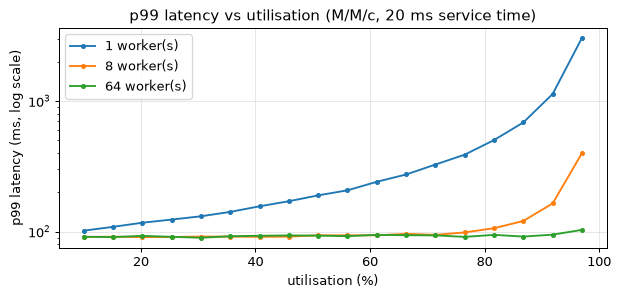

In [18]:
def erlang_c(c, a):
    # probability that an arriving request must wait; a = lambda/mu (offered load), c = workers
    if a >= c:
        return 1.0
    b = 1.0
    for k in range(1, c + 1):            # Erlang B by a stable recursion
        b = a * b / (k + a * b)
    rho = a / c
    return b / (1 - rho * (1 - b))

def mmc_response_samples(lam, mu, c, n=40_000):
    # samples of total time in system (wait + service) for an M/M/c queue
    a = lam / mu
    if a >= c:
        return np.full(n, np.inf)
    p_wait = erlang_c(c, a)
    waits = np.where(rng.random(n) < p_wait, rng.exponential(1 / (c * mu - lam), n), 0.0)
    return waits + rng.exponential(1 / mu, n)

MU = 50.0                                # one worker serves 50 req/s -> 20 ms average service time
utils = np.linspace(0.10, 0.97, 18)
curves = {}
for c in [1, 8, 64]:
    curves[c] = [np.percentile(mmc_response_samples(u * c * MU, MU, c), 99) * 1000 for u in utils]

plt.figure()
for c, p99 in curves.items():
    plt.plot(utils * 100, p99, marker="o", ms=3, label=f"{c} worker(s)")
plt.yscale("log"); plt.xlabel("utilisation (%)"); plt.ylabel("p99 latency (ms, log scale)")
plt.title("p99 latency vs utilisation (M/M/c, 20 ms service time)")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

In [19]:
LAM, TARGET_P99_MS = 4_000, 100          # 4,000 req/s arriving; p99 must stay under 100 ms (illustrative)
rows, chosen = [], None
for c in range(int(LAM / MU) + 1, int(LAM / MU) + 30):
    p99 = np.percentile(mmc_response_samples(LAM, MU, c), 99) * 1000
    rows.append({"workers": c, "utilisation": f"{LAM / (c * MU):.1%}", "P(wait)": f"{erlang_c(c, LAM / MU):.1%}",
                 "p99 ms": round(p99, 1)})
    if chosen is None and p99 < TARGET_P99_MS:
        chosen = c
df_q = pd.DataFrame(rows)
print(df_q[df_q["workers"].isin([81, 82, 83, 84, 86, 88, 90, 95, 100, 105])].to_string(index=False))
print(f"\nsmallest worker count with p99 < {TARGET_P99_MS} ms: {chosen}  (bare minimum to not fall behind: {int(LAM / MU) + 1})")

def simulate_mmc(lam, mu, c, n=30_000):
    # discrete-event check: requests arrive, take the earliest free worker, first come first served
    arrivals = np.cumsum(rng.exponential(1 / lam, n))
    service = rng.exponential(1 / mu, n)
    free_at = [0.0] * c
    resp = np.empty(n)
    for i in range(n):
        t_free = heapq.heappop(free_at)
        end = max(arrivals[i], t_free) + service[i]
        heapq.heappush(free_at, end)
        resp[i] = end - arrivals[i]
    return resp[2_000:]                  # drop the warm-up period

sim = simulate_mmc(LAM, MU, chosen)
print(f"discrete-event simulation with {chosen} workers: p50 {np.percentile(sim, 50) * 1000:.1f} ms, "
      f"p99 {np.percentile(sim, 99) * 1000:.1f} ms")

 workers utilisation P(wait)  p99 ms
      81       98.8%   87.1%   131.1
      82       97.6%   75.4%   102.8
      83       96.4%   65.0%    98.8
      84       95.2%   55.7%    95.4
      86       93.0%   40.2%    94.0
      88       90.9%   28.4%    92.0
      90       88.9%   19.5%    93.3
      95       84.2%    6.8%    92.9
     100       80.0%    2.0%    93.1
     105       76.2%    0.5%    90.9

smallest worker count with p99 < 100 ms: 83  (bare minimum to not fall behind: 81)
discrete-event simulation with 83 workers: p50 19.0 ms, p99 95.5 ms


**What just happened?**
- Latency stays flat for a long time and then shoots up as utilisation approaches 100%. That is why capacity plans target 50-70% utilisation, not 95%.
- Bigger pools handle high utilisation better (64 workers at 90% is fine, 1 worker at 90% is not): pooling capacity helps.
- The load is 80 workers' worth (4,000 / 50). 81 workers keep up on average, but most requests wait and p99 misses the target. Two more workers fix it, because a big pool absorbs bursts well.
- After that, extra workers barely help: the remaining p99 is the service time itself (an exponential 20 ms average has a p99 of about 92 ms). To go lower you must make each request faster, not add servers.
- The discrete-event simulation agrees with the formula.

### 7c. Cache hit rate vs database load and p95 latency

Two questions: (1) how big must the cache be to reach a hit rate, and (2) what does the hit rate do to the database and to user latency?

For (1) we use a **Zipf** popularity curve (the item ranked k-th is requested in proportion to 1/k^s), a common model for "a few items are very popular". For (2) the database is an M/M/c pool (from 7b) with a fixed capacity.

In [20]:
N_ITEMS, ZIPF_S = 1_000_000, 0.9        # 1M items; skew s=0.9 (illustrative)
p = np.arange(1, N_ITEMS + 1, dtype=float) ** -ZIPF_S
p /= p.sum()
cum = np.cumsum(p)
print("cache holding the top X% of items -> hit rate (if the cache keeps exactly the hottest items)")
for frac in [0.001, 0.01, 0.05, 0.10, 0.20, 0.50]:
    print(f"  top {frac:>6.1%} -> {cum[int(frac * N_ITEMS) - 1]:.1%}")

cache holding the top X% of items -> hit rate (if the cache keeps exactly the hottest items)
  top   0.1% -> 34.6%
  top   1.0% -> 51.6%
  top   5.0% -> 66.1%
  top  10.0% -> 73.0%
  top  20.0% -> 80.5%
  top  50.0% -> 91.2%


In [21]:
TOTAL_READS = 100_000                    # read requests per second (illustrative)
DB_WORKERS, DB_MU = 150, 200.0           # 150 connections x 200 queries/s each (5 ms) = 30K reads/s capacity
CACHE_MS_MEDIAN, APP_MS = 0.5, 2.0       # cache round trip; fixed app overhead

rows = []
for hit in [0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99]:
    db_qps = (1 - hit) * TOTAL_READS
    util = db_qps / (DB_WORKERS * DB_MU)
    if util >= 1:                                   # more work arrives than the DB can ever finish
        rows.append({"hit rate": f"{hit:.0%}", "DB reads/s": f"{db_qps:,.0f}", "DB utilisation": f"{util:.0%}",
                     "p50 ms": "overloaded", "p95 ms": "overloaded"})
        continue
    n = 40_000
    cache_ms = rng.lognormal(np.log(CACHE_MS_MEDIAN), 0.4, n)
    db_ms = mmc_response_samples(db_qps, DB_MU, DB_WORKERS, n) * 1000
    total = APP_MS + cache_ms + np.where(rng.random(n) < hit, 0.0, db_ms)
    p95 = np.percentile(total, 95)
    rows.append({"hit rate": f"{hit:.0%}", "DB reads/s": f"{db_qps:,.0f}", "DB utilisation": f"{util:.0%}",
                 "p50 ms": round(np.percentile(total, 50), 1),
                 "p95 ms": round(p95, 1)})
print(pd.DataFrame(rows).to_string(index=False))

hit rate DB reads/s DB utilisation     p50 ms     p95 ms
     50%     50,000           167% overloaded overloaded
     60%     40,000           133% overloaded overloaded
     70%     30,000           100% overloaded overloaded
     75%     25,000            83%        2.6       10.5
     80%     20,000            67%        2.6        9.5
     85%     15,000            50%        2.5        8.0
     90%     10,000            33%        2.5        5.9
     95%      5,000            17%        2.5        3.3
     99%      1,000             3%        2.5        3.0


**What just happened?**
- With this skew, caching the hottest 20% of items gives roughly an 80% hit rate: the 80/20 rule appears naturally from a Zipf curve (real skew varies; measure yours).
- Going from 90% to 95% hit rate **halves** database traffic. Each extra "9" of hit rate is worth a lot.
- Below a certain hit rate the database is over capacity and latency is unbounded. This is also why a **cold cache** after a restart, or a cache cluster failure, can take the database down: warm caches gradually and protect the database with load shedding.

### 7d. Autoscaling over a day with a spike

We simulate one day, minute by minute. Traffic follows a daily curve plus a sudden spike at 19:00 (for example a live event or a push notification to everyone). Each server handles 1,000 req/s at 100%; we aim for 60% utilisation.

Three strategies:
1. **Reactive only:** look at a 3-minute average of traffic, add servers that take 4 minutes to boot.
2. **Reactive + warm pool:** same, but 60 pre-initialized servers can join within 1 minute (a warm-pool server waiting costs 15% of a running one; illustrative).
3. **Predictive + warm pool:** also scale ahead using yesterday's curve (10 minutes ahead), plus the warm pool for surprises.

Requests above capacity are **dropped** (load shedding); requests in minutes above 85% utilisation are counted as **slow**.

                       dropped requests dropped % slow % server-hours
reactive only                 5,217,981    0.097%  0.99%         2638
reactive + warm pool                  0    0.000%  0.34%         2854
predictive + warm pool                0    0.000%  0.34%         2863


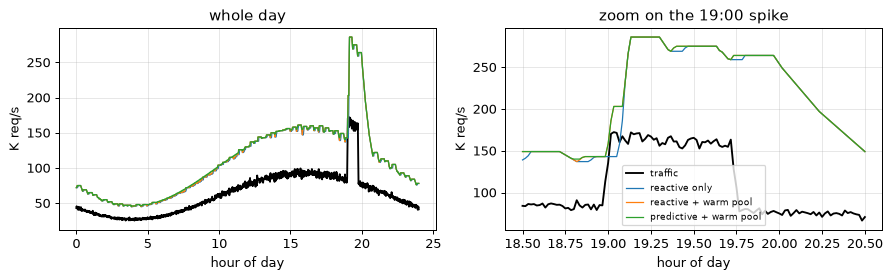

In [22]:
CAP, TARGET, BOOT_MIN, MIN_SERVERS = 1_000, 0.6, 4, 20
minute = np.arange(24 * 60)
hour = minute / 60
daily = 60_000 * (1 + 0.55 * np.sin(2 * np.pi * (hour - 10) / 24))      # low ~04:00, high ~16:00
spike = ((hour >= 19) & (hour < 19.75)).astype(float)
spike = np.clip(np.convolve(spike, np.ones(3) / 3, mode="same"), 0, 1)  # ramps up over ~3 minutes
load = daily * (1 + rng.normal(0, 0.03, minute.size)) * (1 + 1.0 * spike)   # spike doubles traffic
forecast = daily                                                         # "yesterday's curve" (no spike)

def run_autoscaler(load, warm_pool=0, predictive=False, lead=10, pool_cost=0.15):
    ready = math.ceil(load[0] / (CAP * TARGET))
    booting, pool, pool_refills = [], warm_pool, []
    cooldown, dropped, slow, server_min, cap_hist = 0, 0.0, 0.0, 0.0, []
    for t in range(len(load)):
        ready += sum(1 for b in booting if b <= t); booting = [b for b in booting if b > t]
        pool += sum(1 for b in pool_refills if b <= t); pool_refills = [b for b in pool_refills if b > t]
        capacity = ready * CAP
        served = min(load[t], capacity)
        dropped += (load[t] - served) * 60                          # req/s x 60 s
        if load[t] / capacity > 0.85:
            slow += served * 60
        server_min += ready + len(booting) + pool_cost * warm_pool
        cap_hist.append(capacity)
        observed = load[max(0, t - 2): t + 1].mean()                 # metrics arrive as a 3-minute average
        need = math.ceil(observed / (CAP * TARGET))
        if predictive:
            need = max(need, math.ceil(forecast[min(t + lead, len(load) - 1)] / (CAP * TARGET)))
        need = max(need, MIN_SERVERS)
        have = ready + len(booting)
        if need > have:
            extra = need - have
            warm = min(extra, pool)
            pool -= warm
            booting += [t + 1] * warm + [t + 1 + BOOT_MIN] * (extra - warm)
            pool_refills += [t + 1 + BOOT_MIN] * warm               # pool refills itself in the background
            cooldown = 15
        elif need < ready and cooldown == 0:
            ready -= min(ready - need, max(1, ready // 50))          # scale in slowly (at most ~2% per minute)
        cooldown = max(0, cooldown - 1)
    total = load.sum() * 60
    return {"dropped requests": f"{dropped:,.0f}", "dropped %": f"{dropped / total:.3%}",
            "slow %": f"{slow / total:.2%}", "server-hours": round(server_min / 60)}, np.array(cap_hist)

strategies = {"reactive only": dict(), "reactive + warm pool": dict(warm_pool=60),
              "predictive + warm pool": dict(warm_pool=60, predictive=True)}
results, caps = {}, {}
for name, kw in strategies.items():
    results[name], caps[name] = run_autoscaler(load, **kw)
print(pd.DataFrame(results).T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (lo, hi) in zip(axes, [(0, 24), (18.5, 20.5)]):
    m = (hour >= lo) & (hour <= hi)
    ax.plot(hour[m], load[m] / 1000, color="black", lw=1.5, label="traffic")
    for name in strategies:
        ax.plot(hour[m], caps[name][m] / 1000, lw=1, label=name)
    ax.set_xlabel("hour of day"); ax.set_ylabel("K req/s"); ax.grid(alpha=0.3)
axes[0].set_title("whole day"); axes[1].set_title("zoom on the 19:00 spike"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**What just happened?**
- The slow daily curve is easy for every strategy: 60% target utilisation leaves enough headroom while new servers boot.
- The spike is where they differ. **Reactive only** reacts late (metric delay + boot time) and drops requests for several minutes. A **warm pool** cuts the reaction time to about a minute for a modest standing cost (about 8% more server-hours in this toy).
- **Predictive** scaling adds little in this toy, because the daily curve changes slowly and our boot time is short. It matters when ramps are steep (a morning rush), when boot and warm-up take many minutes (big models on GPUs), or for known events you can schedule. It cannot predict a surprise spike; that is the warm pool's job.
- Takeaways: know your scale-up lag; keep headroom; pre-warm before known events (launches, matches, holidays); and have load shedding ready for what you did not predict.

### 7e. Fan-out tail latency: the p99 of the slowest of N calls

When one request calls N backends in parallel and must wait for all of them (search across shards, a feed hydrating many items), its latency is the **maximum** of N latencies. If each call is slow 1% of the time, the chance that at least one of N is slow is 1 - 0.99^N. This is the core point of Dean and Barroso's "The Tail at Scale". Depth (hedged requests, partial results) is in [22/11](11_rag_at_scale_100_million_pdfs_low_latency.ipynb).

In [23]:
def call_latency_ms(size):
    base = rng.lognormal(np.log(10), 0.3, size)                       # typical call ~10 ms
    hiccup = rng.random(size) < 0.01                                  # 1% of calls hit a pause (GC, noisy neighbour)
    return base + hiccup * rng.uniform(80, 200, size)

TRIALS, rows = 20_000, []
for n in [1, 5, 10, 50, 100]:
    lat = call_latency_ms((TRIALS, n))
    worst = lat.max(axis=1)
    # hedging: if a call is not back by 25 ms, send a backup copy and take whichever finishes first
    backup = 25 + call_latency_ms((TRIALS, n))
    hedged = np.minimum(lat, np.where(lat > 25, backup, np.inf)).max(axis=1)
    rows.append({"fan-out N": n, "P(at least one slow call)": f"{1 - 0.99 ** n:.0%}",
                 "p50 ms": round(np.percentile(worst, 50), 1), "p99 ms": round(np.percentile(worst, 99), 1),
                 "p99 ms with hedging": round(np.percentile(hedged, 99), 1)})
print(pd.DataFrame(rows).to_string(index=False))

 fan-out N P(at least one slow call)  p50 ms  p99 ms  p99 ms with hedging
         1                        1%    10.0    28.0                 28.0
         5                        5%    14.2   186.4                 38.4
        10                       10%    16.0   196.4                 39.7
        50                       39%    22.2   208.6                 44.8
       100                       63%   127.8   210.7                 50.6


**What just happened?** One call is usually fast, but at N=100 almost every request includes at least one slow call, so even the *median* request is slow. Hedging (sending a backup copy of a late call, at the price of a few percent extra load) brings the tail back down. Fewer, bigger fan-outs and timeouts with partial results also help.

### 7f. Fan-out on write vs on read, with celebrities

We build a toy social graph where popularity is very uneven (a heavy-tailed **Pareto** distribution, where a few accounts get most followers). Then we count the database/cache operations per day for push, pull and hybrid.

edges: 5,430,376 | median followers: 67 | max followers: 13,564 (27% of all users)
                                         strategy writes/day reads/day largest burst from one post  extra fetches per feed load total ops/day
                          push (fan-out on write)      1.62M   400.00K                      13.56K                          0.0         2.02M
                           pull (fan-out on read)     15.02K    43.44M                           1                        108.6        43.46M
hybrid: no push above 10,000 followers (2 celebs)      1.61M   593.94K                       9.93K                          0.5         2.20M
hybrid: no push above 5,000 followers (11 celebs)      1.59M     1.10M                       4.57K                          1.7         2.69M
hybrid: no push above 2,000 followers (87 celebs)      1.54M     2.85M                       1.99K                          6.1         4.39M

one post by the top account under pure push = 13,564 timeline in

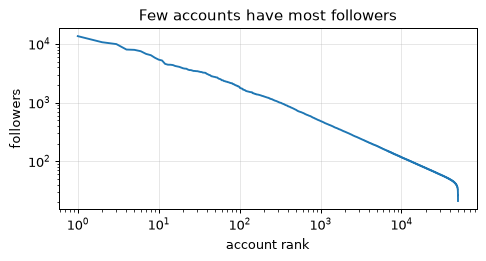

In [24]:
N_USERS = 50_000
popularity = rng.pareto(1.6, N_USERS) + 1                 # heavy tail: a few accounts are hugely popular
p_follow = popularity / popularity.sum()
follows_per_user = rng.integers(20, 200, N_USERS)         # each user follows 20-199 accounts
followers_of = np.repeat(np.arange(N_USERS), follows_per_user)
followees = rng.choice(N_USERS, size=followers_of.size, p=p_follow)
edges = np.unique(followers_of.astype(np.int64) * N_USERS + followees)   # remove duplicate follows
edges = edges[(edges // N_USERS) != (edges % N_USERS)]                 # no self-follows
src, dst = edges // N_USERS, edges % N_USERS                           # src follows dst
followers = np.bincount(dst, minlength=N_USERS)
following = np.bincount(src, minlength=N_USERS)

POSTS_PER_DAY = rng.poisson(0.3, N_USERS)                # posts per user per day (illustrative)
READS_PER_DAY = 8                                        # feed loads per user per day (illustrative)
print(f"edges: {edges.size:,} | median followers: {np.median(followers):.0f} | "
      f"max followers: {followers.max():,} ({followers.max() / N_USERS:.0%} of all users)")

def costs(threshold):
    celeb = followers > threshold
    push_writes = (POSTS_PER_DAY * followers * ~celeb).sum()           # timeline inserts for non-celebrities
    celebs_followed = np.bincount(src[celeb[dst]], minlength=N_USERS)  # how many celebrities each user follows
    reads = (READS_PER_DAY * (1 + celebs_followed)).sum()              # own timeline + one fetch per celebrity
    biggest_burst = followers[~celeb].max()                            # largest number of inserts from ONE post
    return push_writes, reads, celeb.sum(), biggest_burst, celebs_followed.mean()

rows = []
pw, _, _, burst, _ = costs(np.inf)
rows.append({"strategy": "push (fan-out on write)", "writes/day": pw, "reads/day": READS_PER_DAY * N_USERS,
             "largest burst from one post": burst, "extra fetches per feed load": 0.0})
rows.append({"strategy": "pull (fan-out on read)", "writes/day": POSTS_PER_DAY.sum(),
             "reads/day": (READS_PER_DAY * following).sum(), "largest burst from one post": 1,
             "extra fetches per feed load": following.mean()})
for th in [10_000, 5_000, 2_000]:
    w, r, nc, burst, extra = costs(th)
    rows.append({"strategy": f"hybrid: no push above {th:,} followers ({nc} celebs)", "writes/day": w, "reads/day": r,
                 "largest burst from one post": burst, "extra fetches per feed load": extra})
df_f = pd.DataFrame(rows)
df_f["extra fetches per feed load"] = df_f["extra fetches per feed load"].round(1)
df_f["total ops/day"] = df_f["writes/day"] + df_f["reads/day"]
for col in ["writes/day", "reads/day", "total ops/day", "largest burst from one post"]:
    df_f[col] = df_f[col].map(human)
print(df_f.to_string(index=False))

top = followers.argmax()
print(f"\none post by the top account under pure push = {followers[top]:,} timeline inserts; "
      f"at 50K inserts/s that takes {followers[top] / 50_000:.1f} s here, "
      f"and minutes for an account with tens of millions of followers")

plt.figure(figsize=(5.5, 3))
plt.loglog(np.arange(1, N_USERS + 1), np.sort(followers)[::-1])
plt.xlabel("account rank"); plt.ylabel("followers"); plt.title("Few accounts have most followers")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**What just happened?**
- **Pull** makes every feed load fetch from ~100 accounts: reads explode. That is why pure pull is rare for big feeds.
- **Push** has the fewest total operations here, because feed loads far outnumber posts. That is why push is the usual default. Its weak spot is the **burst**: one celebrity post means one insert per follower, all at once (here over ten thousand; at real scale tens of millions, taking minutes and delaying everyone else's posts in the same queue). In real products celebrities also tend to post more often than our flat 0.3 posts/day, which makes this worse.
- **Hybrid** caps the largest burst at the threshold, at the price of a few extra fetches per feed load. Those extra fetches read the recent posts of a small set of very popular accounts, which stay hot in cache, so they are cheap. The threshold is a tuning knob.
- Our toy graph is tiny (in it the top account is followed by about a quarter of all users); real graphs are far bigger and do not scale linearly, but the shape of the trade-off is the same.

## 8. Checklist, common mistakes, recap, interview questions

### 8.1 One-page checklist for a scalable architecture

| Area | Check |
|---|---|
| Requirements | functional list; non-functional targets written as numbers (latency percentiles, availability, durability, freshness) |
| Estimation | DAU, peak QPS, read/write ratio, storage per year, egress, hot set, server and shard counts, rough cost; key assumptions labelled |
| Entry | GeoDNS/anycast, CDN, WAF/DDoS protection, L4/L7 LB, API gateway with auth and rate limits |
| Compute | stateless app tier; sessions in a shared store or tokens; autoscaling with headroom; warm pool for spikes |
| Data | store per access pattern; shard key matches main query; plan for hot keys; replicas with read-your-writes where needed |
| Caching | cache-aside with TTL + jitter; stampede protection; cache failure does not kill the DB |
| Async | queues for slow work; streams for events; idempotent consumers; DLQ; partitions sized for future consumers |
| Resilience | timeouts everywhere; retries with backoff, jitter and budget at one layer; circuit breakers; bulkheads; load shedding; graceful degradation |
| Scale-out | multi-zone by default; multi-region and cells when blast radius or latency demands it |
| Operations | metrics/logs/traces; SLOs and error budgets; canary + feature flags; runbooks; on-call |
| Security and privacy | authN/authZ per service; secrets manager; encryption; data residency; retention and deletion |
| DR | RPO/RTO written down; backups restored in drills; chaos tests |
| Cost | cost per user tracked; biggest line items known; autoscale down; storage lifecycle |
| AI | GPU capacity at peak; routing; caching; quotas per tier; degradation ladder; cost per user per month |

### 8.2 Common interview mistakes

- Jumping to boxes (Kafka! Kubernetes!) before asking requirements and doing estimation.
- Designing for 100M users with no numbers, or numbers with no stated assumptions.
- Sizing for average traffic instead of peak.
- Forgetting that the database (not the app tier) is usually the hard part; sharding with a key that does not match the main query.
- Ignoring hot keys and celebrities.
- Adding a cache without saying how it is invalidated, or what happens when it is cold.
- Retrying at every layer; no timeouts.
- Choosing microservices by default with no reason; or claiming "exactly-once" delivery over a network without explaining dedupe.
- Strong consistency everywhere (slow and fragile) or eventual consistency for money (wrong).
- No failure story: what happens when a zone, a region, the cache, or a dependency is down?
- No monitoring, deployment or cost story.
- For AI features: ignoring GPU capacity and cost per user, and having no fallback when the model is slow.

### 8.3 Recap cheat sheet

| Problem | Typical fix |
|---|---|
| one machine too small / single point of failure | separate DB; horizontal app tier behind a LB |
| app servers hold state | sessions in a shared store or signed tokens |
| too many DB reads | cache + read replicas |
| stale reads after own write | read-your-writes (read primary briefly, or wait for replica position) |
| hot key expiry floods DB | single-flight, locks, stale-while-revalidate, TTL jitter |
| heavy static/media traffic | CDN, compression, right-sized images |
| slow work in the request | queue + idempotent workers + DLQ |
| DB too big or too many writes | federation, then sharding with a good key; NoSQL for simple huge patterns |
| one key too hot | cache replication, key salting, special-case celebrities |
| full-text search | separate search index fed by CDC |
| users far away / region outage | multi-region with GeoDNS; active-active with a conflict plan |
| one failure hurts everyone | cells; roll out per cell |
| latency explodes at high utilisation | keep 50-70% target; add capacity before the knee |
| tail latency in fan-out | fewer calls, hedging, timeouts with partial results |
| traffic spike | headroom, warm pools, predictive scaling, load shedding |
| GPU cost for AI | routing, caching, batching, quotas, shorter contexts |

### 8.4 Interview questions

**Q1. How would you start a "design X for 100M users" question?**
Ask about the main features and the non-functional targets (latency, availability, consistency, data retention). Then estimate DAU, peak QPS, read/write ratio, storage and bandwidth. Then draw a simple high-level design and deep dive into the parts that the numbers say are hard.

**Q2. Why make app servers stateless?**
So any server can handle any request: the load balancer can spread load freely, autoscaling can add or remove servers at any time, and a crash loses no user state. State goes to a shared store, the database, or signed tokens.

**Q3. What is replication lag and how do you handle read-your-writes?**
Replicas apply the primary's changes slightly later. A user who just wrote may read old data from a replica. Fix by reading that user's own data from the primary for a short time after a write, or by reading only from replicas that have caught up to the write's log position.

**Q4. How do you choose a shard key?**
High cardinality, even spread, matches the most common query (so most queries hit one shard), and does not change. For example `user_id` for user data and `conversation_id` for messages. Avoid time or low-cardinality keys for write-heavy tables.

**Q5. What is the celebrity problem in a news feed and how do you solve it?**
With fan-out on write, one post by an account with millions of followers creates millions of timeline writes and delays. Use a hybrid: push for normal accounts; for celebrities, store the post once and merge it into followers' feeds at read time.

**Q6. Why not run servers at 95% utilisation to save money?**
Queueing: as utilisation nears 100%, waiting time grows sharply, so p99 latency explodes and small bursts cause overload. Target 50-70% (higher for large pools) and keep headroom for failures and spikes.

**Q7. How do you protect a service from a sudden 2x traffic spike?**
Rate limits at the edge, headroom, autoscaling with warm pools, caching, queues for non-urgent work, load shedding of low-priority requests, and graceful degradation. Pre-scale before known events.

**Q8. Active-passive vs active-active multi-region?**
Active-passive is simpler (one writer region) but failover is slower and the standby is idle. Active-active serves users from the nearest region and fails over quickly, but needs a plan for conflicting writes (home region per user, mergeable data types, or a globally consistent store for critical data).

**Q9. What is a cell-based architecture and why use it?**
The system is split into independent full-stack cells, each serving a fixed set of users through a simple router. A failure or bad deploy hurts only one cell, which limits the blast radius and allows safer, gradual rollouts.

**Q10. How do you estimate GPUs for an AI assistant with 100M users?**
Estimate assistant users and messages per day, convert to peak requests per second, subtract cache hits, multiply by GPU-seconds per request (prefill + decode at your chosen batch size), weight by the small/large model mix, and divide by target utilisation. Check with Little's law (concurrency = rate x stream time). Then cut the number with routing, caching, shorter contexts and batch jobs.

**Q11. Exactly-once delivery in a chat app?**
Over a network you get at-least-once at best. Make it look exactly-once: client-generated message ids (idempotency keys), server dedupe, per-conversation sequence numbers, and clients that drop duplicates and sync from their last sequence number.

## Further reading

Books and papers:
- Martin Kleppmann, *Designing Data-Intensive Applications* (O'Reilly). The best single book on replication, partitioning, consistency and streams. https://dataintensive.net
- Jeffrey Dean and Luiz Andre Barroso, "The Tail at Scale", *Communications of the ACM*, 2013 (fan-out tail latency, hedged requests).
- Betsy Beyer, Chris Jones, Jennifer Petoff, Niall Richard Murphy (eds.), *Site Reliability Engineering* (the Google SRE book), and *The Site Reliability Workbook*: SLOs, error budgets, load shedding, overload handling. https://sre.google/books/
- Mor Harchol-Balter, *Performance Modeling and Design of Computer Systems: Queueing Theory in Action* (M/M/c and Erlang C).
- Marc Brooker, "Exponential Backoff And Jitter" (AWS Architecture Blog, 2015).
- AWS Well-Architected Framework (reliability, performance, cost pillars). https://aws.amazon.com/architecture/well-architected/
- AWS whitepaper "Reducing the Scope of Impact with Cell-Based Architecture" (cells and blast radius).
- Twitter Engineering, "Announcing Snowflake" (2010), the original Snowflake id scheme.

System design guides used to check the topic list and the classic worked designs for this notebook (all text here is our own wording):
- donnemartin, *The System Design Primer* (scalability, DNS, CDN, load balancer, database, cache, asynchronism sections). https://github.com/donnemartin/system-design-primer
  - "Design a system that scales to millions of users on AWS". https://github.com/donnemartin/system-design-primer/blob/master/solutions/system_design/scaling_aws/README.md
  - "Design the Twitter timeline and search" (fan-out service). https://github.com/donnemartin/system-design-primer/blob/master/solutions/system_design/twitter/README.md
- ByteByteGo, *System Design 101* (general visual guides, including polling vs SSE vs WebSocket and load balancer vs API gateway). https://github.com/ByteByteGoHq/system-design-101
- ashishps1, *Awesome System Design Resources* (topic list and interview problems). https://github.com/ashishps1/awesome-system-design-resources
- Karan Pratap Singh, *System Design* course (WhatsApp and Twitter chapters; API gateway, CQRS, rate limiting, idempotency, disaster recovery). https://github.com/karanpratapsingh/system-design
- GeeksforGeeks System Design tutorial pages:
  - System Design Tutorial: https://www.geeksforgeeks.org/system-design/system-design-tutorial/
  - What is Scalability: https://www.geeksforgeeks.org/system-design/what-is-scalability/
  - Load balancer interview questions: https://www.geeksforgeeks.org/system-design/load-balancer-system-design-interview-question/
  - Caching for beginners: https://www.geeksforgeeks.org/system-design/caching-system-design-concept-for-beginners/
  - Database sharding: https://www.geeksforgeeks.org/system-design/database-sharding-a-system-design-concept/
  - CAP theorem: https://www.geeksforgeeks.org/system-design/cap-theorem-in-system-design/
  - Designing WhatsApp Messenger: https://www.geeksforgeeks.org/system-design/designing-whatsapp-messenger-system-design/
  - Design Twitter (fan-out strategy, Snowflake ids): https://www.geeksforgeeks.org/interview-experiences/design-twitter-a-system-design-interview-question/

Related notebooks in this repo:
- [23_Software_Engineering/09_system_design_fundamentals](../23_Software_Engineering/09_system_design_fundamentals.ipynb), [01_hld_ml_systems](01_hld_ml_systems.ipynb), [04_nosql_and_data_stores](04_nosql_and_data_stores.ipynb), [06_ml_system_components](06_ml_system_components.ipynb), [08_industry_system_design_case_study](08_industry_system_design_case_study.ipynb), [09_ai_system_design_for_llm_applications](09_ai_system_design_for_llm_applications.ipynb), [10_distributed_systems_and_architecture_patterns](10_distributed_systems_and_architecture_patterns.ipynb), [11_rag_at_scale_100_million_pdfs_low_latency](11_rag_at_scale_100_million_pdfs_low_latency.ipynb)
- [16_Deployment/05_industry_safe_model_rollout_strategies](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb), [15_MLOps/16_observability_hands_on](../15_MLOps/16_observability_hands_on.ipynb), [17_Docker/kubernetes/01_kubernetes](../17_Docker/kubernetes/01_kubernetes.ipynb), [18_Cloud/04_cloud_cost_optimization](../18_Cloud/04_cloud_cost_optimization.ipynb), [13_Databases/09_indexing_patterns_database_and_vector_side_by_side](../13_Databases/09_indexing_patterns_database_and_vector_side_by_side.ipynb)
- [08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag](../08_LLM/23_llm_caching_kv_cache_prompt_semantic_cag.ipynb), [08_LLM/27_tokens_cost_batch_and_caching_llm_apis](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb)

In [25]:
print(f"Notebook finished in {time.time() - NOTEBOOK_START:.1f} s")

Notebook finished in 7.9 s
